# 3. 리스테리아 예측인자 — 식정원 DB 수집 · 상태 확인 · 우리 데이터 조인

**작성 2026-09-14** · DB `TOXIN_MODEL_PRED` (PostgreSQL 18, 10.31.72.23:5432, 계정 `nfsi_user`, **읽기 전용 세션**) · 기준 데이터 `data/listeria_body.parquet` (676,537행 × 23열)

## 흐름

| 장 | 내용 | 산출물 (`data/collected/`) |
|---|---|---|
| 1 | 환경 준비, DB 읽기 전용 접속 확인 | – |
| 2 | **무엇을 모으나**: PPT 예측인자 → 데이터출처.xlsx 빨간 항목 → 매핑 엑셀(시트1·2 = DB 컬럼, 시트3 = DB 에 없음) | – |
| 3 | **몸통 확인**: DB `ready_data.hazard_preprocessed_data`(리스테리아) ↔ 우리 parquet, 조인 기준 확정 | `00_body_db.parquet` |
| 4 | **조인키 검증**: 수집 전에 키가 실제로 맞는지 매칭 수로 확인 | – |
| 5 | **DB 수집 + 상태 확인**: 행 단위 속성(LIMS·대장·분류·수입) / 국내 기상(ASOS·NAS) / 토양 pH / 대기 / 해외 기상 / 코드표 | `02*_*.parquet`, `3*_*.parquet`, `4*`, `5*`, `6*` |
| 6 | **조인**: 키 조인 → 최근접 관측소 → 기준일 창(D0·7일·30일) → 토양·대기·해외 | `listeria_joined.parquet` |
| 7 | (참고) 수분활성도·식품 pH·염도 — 리서치팀 파일 = DB `t_aw_cl` 확인 후 품목코드로 조인 | `file_*` 컬럼 |
| 8 | **결과**: 커버리지, 누수 점검, 매핑 컬럼별 수집 여부, 인자별 상태, 시트3 수집방안·근거 검증 | `coverage_summary.csv` |

## 원칙
* DB 에서는 **SELECT 만** 실행한다(회사 공용 계정). `db_utils.connect()` 가 내 세션에만 `default_transaction_read_only=on` 을 켠다. TEMP 테이블·인덱스·설정 변경 없음.
* 결과는 `data/collected/` 에 parquet 로 저장하고, 파일이 있으면 DB 대신 파일을 읽는다(재실행 안전). 새로 받으려면 `FORCE = True`.
* **조인 기준은 우리 parquet 676,537행**(left join, 행 수 불변을 매 단계 `assert`). DB 몸통에만 있는 행은 3장에서 확인만 한다.
* **기준일 `base_date`** = parquet `mnfctur_de` (= DB `mnfctur_de_or_fallback`: 제조일 → 의뢰일 → 선적일 순 fallback. 3장에서 100% 일치 확인). 기상·대기 창은 기준일 **포함 과거**만 본다.

## 1. 환경 준비

In [1]:
import sys, time, re, gc, decimal, datetime as dt, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import Image, display
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 80); pd.set_option('display.width', 220); pd.set_option('display.max_colwidth', 80)
matplotlib.rcParams['font.family'] = 'Malgun Gothic'; matplotlib.rcParams['axes.unicode_minus'] = False

# 경로: 이 노트북은 리스테리아ML/notebook/ 에 있다
_cand = Path.cwd().parent
ROOT = _cand if (_cand / 'data' / 'listeria_body.parquet').exists() else Path(r'C:\Users\NT751\Desktop\천영진\리스테리아ML')
DATA, OUT, SCRIPTS, DOCS = ROOT / 'data', ROOT / 'data' / 'collected', ROOT / 'scripts', ROOT / 'docs'
RESEARCH = ROOT.parent / '리서치팀문서'
OUT.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(SCRIPTS))
from db_utils import connect, pgpass_entry     # 비밀번호는 %APPDATA%\postgresql\pgpass.conf 에서 libpq 가 읽음

FORCE = False
print('ROOT =', ROOT); print('저장 =', OUT); print('pandas', pd.__version__, '| numpy', np.__version__)

ROOT = C:\Users\NT751\Desktop\천영진\리스테리아ML
저장 = C:\Users\NT751\Desktop\천영진\리스테리아ML\data\collected
pandas 3.0.3 | numpy 2.5.1


### 1-1. DB 읽기 전용 접속

In [2]:
conn = connect()      # readonly=True (기본) → 세션 옵션 -c default_transaction_read_only=on
with conn.cursor() as cur:
    cur.execute("SELECT version(), current_user, current_database(), current_setting('default_transaction_read_only'), now()")
    ver, usr, dbn, ro, now = cur.fetchone()
e = pgpass_entry()
print(f"{e['host']}:{e['port']} | db {dbn} | user {usr} | read_only={ro} | {ver.split(',')[0]} | 서버시각 {now:%Y-%m-%d %H:%M}")
assert ro == 'on', '읽기 전용 세션이 아님'

10.31.72.23:5432 | db TOXIN_MODEL_PRED | user nfsi_user | read_only=on | PostgreSQL 18.4 on x86_64-windows | 서버시각 2026-09-14 15:18


### 1-2. 공통 헬퍼

In [3]:
LOG = []   # 수집 로그

def fix_types(df):
    """psycopg 결과: Decimal → float, date → datetime (parquet 저장용)"""
    for c in df.columns:
        s = df[c]
        if s.dtype == object:
            nn = s.dropna()
            if len(nn) == 0:
                continue
            v = nn.iloc[0]
            if isinstance(v, decimal.Decimal):
                df[c] = pd.to_numeric(s, errors='coerce').astype('float64')
            elif isinstance(v, (dt.datetime, dt.date)):
                df[c] = pd.to_datetime(s, errors='coerce')
    return df

def fetch(sql, label, params=None):
    """서버측 커서로 10만 행씩 받기 (읽기 전용 트랜잭션)"""
    t0 = time.time()
    with conn.transaction():
        with conn.cursor(name=f"cur_{label}_{int(t0)}") as cur:
            cur.execute(sql, params)
            cols = [d.name for d in cur.description]
            chunks = []
            while True:
                rows = cur.fetchmany(100_000)
                if not rows:
                    break
                chunks.append(pd.DataFrame(rows, columns=cols))
    df = pd.concat(chunks, ignore_index=True) if chunks else pd.DataFrame(columns=cols)
    return fix_types(df)

def collect(name, sql, params=None, source=''):
    """OUT/name.parquet 가 있으면 읽고, 없으면 DB 에서 받아 저장"""
    path = OUT / f'{name}.parquet'
    t0 = time.time()
    if path.exists() and not FORCE:
        df, how = pd.read_parquet(path), '캐시'
    else:
        df, how = fetch(sql, name, params), 'DB'
        df.to_parquet(path, index=False)
    sec = round(time.time() - t0)
    LOG.append({'파일': path.name, 'DB 원천': source, '방식': how, '행': len(df), '열': df.shape[1], '초': sec})
    print(f"[{name}] {how}: {len(df):,}행 × {df.shape[1]}열 ({sec}초) ← {source}")
    return df

def query(sql, params=None):
    """작은 검증 쿼리"""
    t0 = time.time()
    with conn.cursor() as cur:
        cur.execute(sql, params)
        df = pd.DataFrame(cur.fetchall(), columns=[d.name for d in cur.description])
    print(f"  ({time.time() - t0:.1f}초)")
    return fix_types(df)

def nn_table(df, cols, by='src_route'):
    """컬럼별 비결측 비율(%) — 국내/수입 따로"""
    rows = []
    for c in cols:
        r = {'컬럼': c}
        for g, sub in df.groupby(by, observed=True):
            r[f'비결측%_{g}'] = round(sub[c].notna().mean() * 100, 1)
        r['전체%'] = round(df[c].notna().mean() * 100, 1)
        rows.append(r)
    return pd.DataFrame(rows)

def to_obj(s):
    """category/str → object (결측은 None)"""
    return s.astype(object).where(s.notna(), None)

## 2. 무엇을 모으나

1. **PPT (예측인자 정리 ppt.jpg)** — 식정원 리서치팀이 정한 리스테리아 예측인자 우선순위·추가 인자.
2. **위해요소별_중요인자_데이터출처.xlsx** — 인자별 공공데이터 출처. D열 **빨간 글자**가 수집 대상 핵심 인자(파랑·검정은 비대상).
3. **docs/02_데이터수집/리스테리아_수집변수_매핑.xlsx** — 1·2 를 DB 테이블정의서와 대조한 결과. 시트1 빨간항목→DB 컬럼, 시트2 PPT 인자→DB 컬럼, **시트3 DB 에 없어 외부 수집이 필요한 항목**, 시트6 조인키.

### 2-1. PPT 예측인자

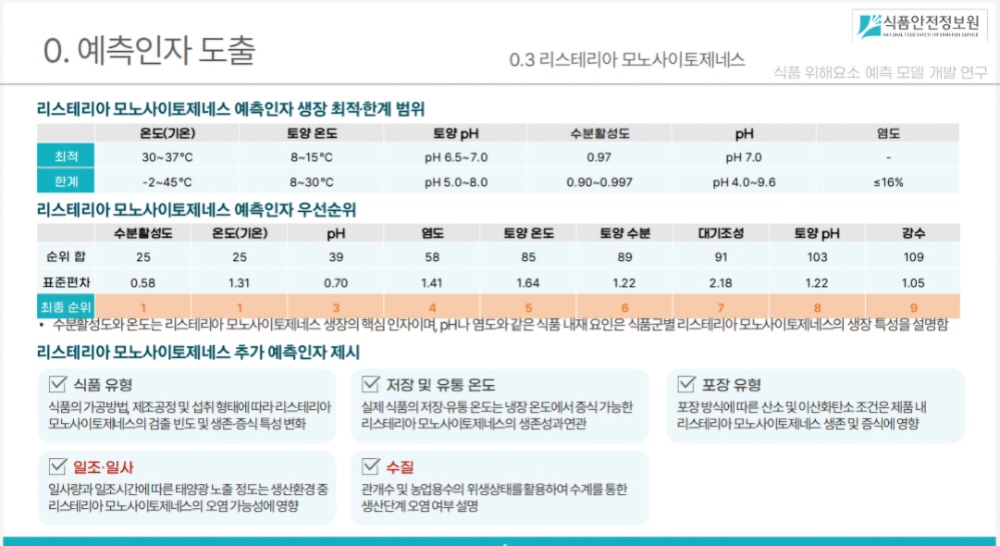

,인자,순위 합,표준편차,PPT 최종 순위,생장 최적,생장 한계
0,수분활성도,25,0.58,1,0.97,0.90~0.997
1,온도(기온),25,1.31,1,30~37℃,-2~45℃
2,pH,39,0.70,3,7.0,4.0~9.6
3,염도,58,1.41,4,-,≤16%
4,토양 온도,85,1.64,5,8~15℃,8~30℃
5,토양 수분,89,1.22,6,,
6,대기조성,91,2.18,7,,
7,토양 pH,103,1.22,8,6.5~7.0,5.0~8.0
8,강수,109,1.05,9,,


,PPT 추가 인자,설명
0,식품 유형,가공방법·제조공정·섭취 형태에 따라 검출 빈도·생존·증식 특성 변화
1,저장 및 유통 온도,냉장 온도에서 증식 가능한 리스테리아의 생존성과 연관
2,포장 유형,포장 방식에 따른 산소·이산화탄소 조건이 생존·증식에 영향
3,일조·일사,태양광 노출 정도 → 생산환경 중 오염 가능성
4,수질,관개수·농업용수 위생상태 → 수계를 통한 생산단계 오염


In [4]:
display(Image(filename=str(RESEARCH / '예측인자 정리 ppt.jpg'), width=900))
ppt_rank = pd.DataFrame([('수분활성도', 25, 0.58, 1, '0.97', '0.90~0.997'), ('온도(기온)', 25, 1.31, 1, '30~37℃', '-2~45℃'), ('pH', 39, 0.70, 3, '7.0', '4.0~9.6'),
                         ('염도', 58, 1.41, 4, '-', '≤16%'), ('토양 온도', 85, 1.64, 5, '8~15℃', '8~30℃'), ('토양 수분', 89, 1.22, 6, '', ''),
                         ('대기조성', 91, 2.18, 7, '', ''), ('토양 pH', 103, 1.22, 8, '6.5~7.0', '5.0~8.0'), ('강수', 109, 1.05, 9, '', '')],
                        columns=['인자', '순위 합', '표준편차', 'PPT 최종 순위', '생장 최적', '생장 한계'])
ppt_extra = pd.DataFrame([('식품 유형', '가공방법·제조공정·섭취 형태에 따라 검출 빈도·생존·증식 특성 변화'),
                          ('저장 및 유통 온도', '냉장 온도에서 증식 가능한 리스테리아의 생존성과 연관'),
                          ('포장 유형', '포장 방식에 따른 산소·이산화탄소 조건이 생존·증식에 영향'),
                          ('일조·일사', '태양광 노출 정도 → 생산환경 중 오염 가능성'),
                          ('수질', '관개수·농업용수 위생상태 → 수계를 통한 생산단계 오염')], columns=['PPT 추가 인자', '설명'])
display(ppt_rank); display(ppt_extra)

### 2-2. 데이터출처.xlsx 빨간 항목 (rich-text run 단위 파싱)

In [5]:
import openpyxl
from openpyxl.cell.rich_text import CellRichText, TextBlock
RED = 'FFFF0000'

def red_items(path):
    ws = openpyxl.load_workbook(path, rich_text=True).worksheets[0]
    rows = []
    for row in ws.iter_rows(min_row=2):
        c = row[3]                              # D열 '데이터 제공 항목'
        v, reds = c.value, []
        if v is None:
            continue
        if isinstance(v, CellRichText):
            reds = [str(x) for x in v if isinstance(x, TextBlock) and x.font is not None and x.font.color is not None and x.font.color.rgb == RED]
        elif c.font is not None and c.font.color is not None and c.font.color.rgb == RED:
            reds = [str(v)]
        rows.append({'행': c.row, '데이터명': row[1].value, '제공기관': str(row[2].value).replace('\n', ' '),
                     '빨간 글자': ' || '.join(r.strip() for r in reds), '현재상태': str(row[5].value).replace('\n', ' '), '주기': row[6].value})
    return pd.DataFrame(rows)

src_all = red_items(RESEARCH / '위해요소별_중요인자_데이터출처.xlsx')
red = src_all[src_all['빨간 글자'] != ''].reset_index(drop=True)
print(f"데이터출처 데이터 행 {len(src_all)}개 중 빨간 글자 있는 행 {len(red)}개, 없는 행: {src_all.loc[src_all['빨간 글자'] == '', '행'].tolist()}")
display(red)

데이터출처 데이터 행 21개 중 빨간 글자 있는 행 19개, 없는 행: [17, 22]


,행,데이터명,제공기관,빨간 글자,현재상태,주기
0,2,종관기상관측(ASOS),기상청,"기온, 강수, 바람, || 일조",확보(API) - 데이터포맷: JSON+XML,"시간, 일"
1,3,방재기상관측(AWS),기상청,"기온, 강수, 바람,",확보(API) - 데이터포맷: JSON+XML,"분, 시간, 일"
2,4,농업기상 관측 조회(AAOS),기상청,"기온, 풍속 || 토양수분, || 일조",확보(CSV),"시간, 일"
3,5,농업기상 기본관측 조회,농촌진흥청 국립농업과학원,"기온, 최고기온, 최저기온 || 풍향, 풍속 || 강수량, 일조시간, 일사량",확보(API) - 데이터포맷: XML,"시간, 일"
4,6,농업기상 상세관측 조회,농촌진흥청 국립농업과학원,"기온(40-50-150cm기준 최고, 최저), || 풍향(150-300-400cm, 1000cm), 최대풍속(150-300-1000cm...",확보(API) - 데이터포맷: XML,"10분, 시간, 일, 월"
5,7,토양검정 화학성 상세정보,농촌진흥청 국립농업과학원,"산도(pH)유효인산(mg/kg || 유기물(g/kg),",확보(API) - 데이터포맷: XML,수시
6,8,농업기상 농업용 미래상세 기후도,농촌진흥청 국립농업과학원,"기상요소(월강수량, 월평균기온, 월최고기온, 월최저기온)",확보(PDF),월
7,9,팜맵 기반 농업기상 조회,농림축산식품부 농림수산식품교육문화정보원,"기온(50-150-400cm), 풍향(150-300-1000cm), 풍속(150-300-1000cm), || 강수량, 토양수분값(10-2...",확보(API) - 데이터포맷: JSON+XML,일
8,10,팜맵 기반 토양검정 조회,농림축산식품부 농림수산식품교육문화정보원,"산도, 유기물함량, 유효인산농도,",확보(API) - 데이터포맷: JSON+XML,년
9,11,토양 수분량,한국수자원공사,토양수분량 관측단위(%),확보(CSV),일


### 2-3. 매핑 엑셀 — DB 로 받을 컬럼(시트1·2)과 DB 에 없는 항목(시트3)

In [6]:
MAP_XLSX = DOCS / '02_데이터수집' / '리스테리아_수집변수_매핑.xlsx'
_xl = pd.ExcelFile(MAP_XLSX); print('시트:', _xl.sheet_names)
map1, map2, map3, map6 = (pd.read_excel(MAP_XLSX, sheet_name=i) for i in (0, 1, 2, 5))
m1 = map1[map1['스키마'].notna() & (map1['스키마'] != '(없음)')]
m2 = map2[map2['스키마'].notna() & (map2['스키마'] != '(없음)')]
print(f"시트1 빨간항목→DB: {m1[['스키마','테이블','컬럼']].drop_duplicates().shape[0]}개 컬럼 / 시트2 PPT→DB: {m2[['스키마','테이블','컬럼']].drop_duplicates().shape[0]}개 컬럼")
display(m1.groupby(['변수 그룹', '스키마', '테이블'], sort=False)['컬럼'].agg(', '.join).reset_index())
display(m2.groupby(['우선순위', '변수', '스키마', '테이블'], sort=False)['컬럼'].agg(', '.join).reset_index())

시트: ['1_빨간항목_DB매핑', '2_PPT추가변수_DB매핑', '3_미수집_외부수집필요', '4_추가발굴_제안', '5_빨간항목_원문', '6_조인키_요약']


시트1 빨간항목→DB: 78개 컬럼 / 시트2 PPT→DB: 63개 컬럼


,변수 그룹,스키마,테이블,컬럼
0,기온,api_data_info,kma_asos_daily_info,"avg_ta, max_ta, min_ta, max_ta_hrmt, min_ta_hrmt"
1,기온,api_data_info,nas_agri_weather_daily_info,"temp, hghst_artmp, lowst_artmp"
2,기온,api_data_info,kma_weather_predict_info,"temp, hghst_artmp, lowst_artmp"
3,기온,api_data_info,global_weather_info,"temperature_mean, temperature_max, temperature_min"
4,강수,api_data_info,kma_asos_daily_info,"sum_rn, n99_rn, sum_rn_dur, hr_1_max_rn, mi_10_max_rn"
5,강수,api_data_info,nas_agri_weather_daily_info,rn
6,강수,api_data_info,kma_weather_predict_info,precip_mm
7,강수,api_data_info,global_weather_info,precipitation_sum
8,바람(풍속·풍향),api_data_info,kma_asos_daily_info,"avg_ws, max_ws, max_ws_wd, max_ins_ws, max_ins_ws_wd, max_ws1, hr_24_sum_rws"
9,바람(풍속·풍향),api_data_info,nas_agri_weather_daily_info,"wind, max_wind, widdir"


,우선순위,변수,스키마,테이블,컬럼
0,1,온도(기온),api_data_info,kma_asos_daily_info,"avg_ta, max_ta, min_ta"
1,1,온도(기온),api_data_info,nas_agri_weather_daily_info,temp
2,4,토양온도,api_data_info,kma_asos_daily_info,"avg_cm5_te, avg_cm10_te, avg_cm20_tes, avg_cm30_te, avg_ts"
3,4,토양온도,api_data_info,nas_agri_weather_daily_info,"soil_temp, gr_temp"
4,5,토양 수분,api_data_info,nas_agri_weather_daily_info,soil_wt
5,5,토양 수분,api_data_info,global_weather_info,soil_moisture_mean
6,6,대기 조성,api_data_info,keco_airkorea_fine_dust_info,"no2_value, co_value, so2_value"
7,7,토양 pH,api_data_info,soil_ph_info,acid
8,7,토양 pH,api_data_info,global_soil_ph,ph_mean
9,8,강수,api_data_info,kma_asos_daily_info,sum_rn


In [7]:
print(f'시트3 (DB 에 없음, 외부 수집 필요): {len(map3)}행')
display(map3)
display(map6)

시트3 (DB 에 없음, 외부 수집 필요): 15행


,출처 행,데이터명,제공기관,필요 항목(출처:빨간글씨),DB 상태,현재상태(출처),생산 주기,URL
0,11,토양 수분량,한국수자원공사,토양수분량 관측단위(%) — 용담시험유역 6개 지점 토심별,DB 없음(NAS 단일 토양수분만),확보(CSV),일,https://www.data.go.kr/data/15036932/fileData.do
1,12,주요 유역별 토양수분량 자료,한국수자원조사기술원,"유역별 토양수분량(m³/m³, 850개 표준유역)",DB 없음,"확보(API, CSV) -데이터포맷: JSON+XML",일,https://www.data.go.kr/data/15118456/fileData.do
2,13,흙토람 시스템 토양수분 조회,농촌진흥청 (국립농업과학원),시군별 토양유효수분율(%),DB 없음(직접 조회 사이트),미확보(직접 조회),시간,https://weather.rda.go.kr/weather/soilSttusSensorMap.do?wmsFlag=Y
3,6,농업기상 상세관측 조회,농촌진흥청 국립농업과학원,깊이별 토양수분(10-20-30cm)·높이별 기온·풍향,DB 는 단일 값만,확보(API) - 데이터포맷: XML,"10분, 시간, 일, 월",https://www.data.go.kr/data/15078194/openapi.do
4,8,농업기상 농업용 미래상세 기후도,농촌진흥청 국립농업과학원,월강수량·월평균/최고/최저기온 (SSP/RCP 미래 기후도),DB 없음(예측 시나리오),확보(PDF),월,https://www.data.go.kr/data/15067103/fileData.do#
5,15,"연속정보_염분(3분, 15분)",해양수산부 국립수산과학원,"해수 염분정보(격자, 3분/15분)",DB 없음,확보(API) -데이터포맷: XML,"3분, 15분",(3분)\nhttps://www.data.go.kr/data/15075723/openapi.do\n(15분)\nhttps://www.da...
6,16,연속정보_해상풍(15분),해양수산부 국립수산과학원,"해상풍 풍향·풍속(격자, 15분)",DB 없음(육상 풍속만),확보(API) -데이터포맷: XML,15분,https://www.data.go.kr/data/15075733/openapi.do
7,18,지하수 오염예측도,한국농어촌공사,지하수 오염예측 등급(SHP),DB 없음,확보(SHP),년,https://www.data.go.kr/data/15067857/fileData.do
8,19,지하수 오염취약성도,한국농어촌공사,DRASTIC INDEX 점수(SHP),DB 없음,확보(SHP),년,https://www.data.go.kr/data/15067859/fileData.do
9,20,대기조성(이산화탄소),기상청 종합 기후변화감시정보,이산화탄소(CO2) 월평균·연평균·지점별 농도,DB 없음(co_value 는 CO),"확보(CSV, PNG)","월, 년",https://www.climate.go.kr/home/09_monitoring/ghg/co2_global_trend#


,기준 테이블,기준 키,대상 테이블,대상 키,주의
0,ready_data.hazard_preprocessed_data,"legal_dong_code / lat, lon / mnfctur_de_or_fallback",api_data_info.kma_asos_daily_info,stn_id(최근접 관측소: kma_ground_obs_station_info.lat/lon) + meas_date,기상 결합은 geo_route='domestic' 만(정의서)
1,ready_data.hazard_preprocessed_data,"lat, lon + 기준일",api_data_info.nas_agri_weather_daily_info,obsr_spot_code(최근접: nas_agri_weather_obs_station.instl_la/instl_lo) + meas_date,sun_time·srqty 는 관측소 일부만 보유
2,ready_data.hazard_preprocessed_data,legal_dong_code + 기준일 연도,api_data_info.soil_ph_info,legal_dong_code(10자리) + any_year,exam_day 는 연 집계에 사용하지 않음(정의서)
3,ready_data.hazard_preprocessed_data,"lat, lon + 기준일",api_data_info.keco_airkorea_fine_dust_info,station_nm(측정소: keco_airkorea_obs_station.dm_x/dm_y TM→위경도) + msur_dt,테이블목록: 최근접 30km 매칭
4,ready_data.hazard_preprocessed_data,prdlst_mnfctur_sttemnt_no,ba_data.t_prdlst_mnf_ledg,prdlst_report_no (또는 prdlst_report_ledg_no),수입·농관원 건은 NULL
5,ready_data.hazard_preprocessed_data,bsn_lcns_ledg_no,ba_data.t_bsn_lcns_ledg,bsn_lcns_ledg_no,주소 체인 2순위 테이블
6,ready_data.hazard_preprocessed_data,lims_data_key,ba_data.m_org_lims_data_info,lims_data_key,운반 온도·검사 목적·시료 수 등 원본 컬럼
7,ready_data.hazard_preprocessed_data,cntc_sys_key2(수입 접수번호),ba_data.s_org_lims_data_info,rcept_no,선적·입항·보세 정보
8,ba_data.s_org_lims_data_info,ovsmnfst_cd,ba_data.s_co_ifd_ovsmnfst_regstr_m,ovsmnfst_cd,HACCP·FSMS 여부. 테이블목록 '미사용' → 조인율 확인
9,ba_data.m_org_lims_data_info,*_code (ZIM02/03/08/11/40),ba_data.t_cm_cmmn_code,cmmn_cl_code + cmmn_code → cmmn_code_nm,코드→명칭


### 2-4. 수집 묶음 (이 노트북에서 실제로 받는 단위)

| 파일 | DB 원천 | 조인 키 (우리 데이터 → DB) | 대상 | 인자 |
|---|---|---|---|---|
| `00_body_db` | `ready_data.hazard_preprocessed_data` | `lims_data_key` | 전체 | 조인 키(품목제조번호·영업허가번호·수입접수번호·국가코드·좌표) |
| `02a_m_org` | `ba_data.m_org_lims_data_info` | `lims_data_key` | 전체 | 저장·유통 온도 대체(운반 온도·방법, 시료 상태), 유통일, 식품 유형(상위품목) |
| `02b_ledg` | `ba_data.t_prdlst_mnf_ledg` | `prdlst_mnfctur_sttemnt_no` → `prdlst_report_no` (원문·숫자만 두 형태) | 국내 | 제조조건·보존유통기준·유통기한·포장재질·HACCP |
| `02c_bsn` | `ba_data.t_bsn_lcns_ledg` | `bsn_lcns_ledg_no` | 국내 | 축종·양식종·포장실 면적 |
| `02d_cl` | `ba_data.t_prdlst_cl` | `mapped_prdlst_code` 또는 `prdlst_code` → `prdlst_cd` | 전체 | 식품 유형(품목 계층·식품군·정의) |
| `02e_s_org` / `02f_co` | `ba_data.s_org_lims_data_info` / `s_co_ifd_ovsmnfst_regstr_m` | `cntc_sys_key2` → `rcept_no` / `ovsmnfst_cd` | 수입 | 수입 물류(선적·입항·보세), 제품구분·HSK, 동물성식품 종류 |
| `31_*`, `32_asos_daily`, `33_nas_daily` | `api_data_info.kma_ground_obs_station_info`·`kma_asos_daily_info`, `nas_agri_weather_obs_station`·`nas_agri_weather_daily_info` | 좌표 → 최근접 관측소, `base_date` → 창 | 국내 | 기온·강수·바람·일조·일사·지중온도·토양수분 |
| `41~43_soil*` | `api_data_info.soil_ph_info`, `global_soil_ph` | 법정동+연도 → 시군구 fallback / 국가 | 국내 / 수입 | 토양 pH·유효인산·유기물 |
| `50_air_*` | `api_data_info.keco_airkorea_obs_station`·`keco_airkorea_fine_dust_info` | 좌표 → 최근접 측정소, `base_date` → 창 | 국내 | 대기(NO2·CO·SO2) |
| `60_global_daily`, `61_nation_code` | `api_data_info.global_weather_info`, `ba_data_info.nation_code`(코드 변환표) | 국가 alpha-2 → alpha-3, `base_date` → 창 | 수입 | 기온·강수·습도·토양수분·일조·바람·일사 |
| `70_codes` | `ba_data.t_cm_cmmn_code` (IM08 운반방법·IM11 시료상태·IM40 온도단위·IM02 검사목적·IM03 검사종류) | 코드 → 명칭 | – | 코드 해석 |

> 주의: 정의서·`collect_all.py` 에 적힌 공통코드 분류 `ZIM08/ZIM11/ZIM40` 은 DB 에 0행이다. 실제 분류명은 `IM08/IM11/IM40` (4-5 에서 확인).

## 3. 몸통 확인 — DB 리스테리아 행 ↔ 우리 parquet

우리 parquet(23열)에는 조인에 필요한 키(품목제조번호, 영업허가번호, 수입접수번호, 국가코드 등)가 없다. DB 몸통에서 키 컬럼을 받아 `lims_data_key` 로 붙인다.

In [8]:
pq = pd.read_parquet(DATA / 'listeria_body.parquet')
for c in ['lims_data_key', 'src_route', 'judge_result', 'date_basis', 'prdlst_code', 'train_prdlst_code', 'train_prdlst_nm', 'legal_dong_code', 'addr_source', 'expr_iem_nm', 'inspct_instt_code']:
    pq[c] = to_obj(pq[c])
pq['mnfctur_de'] = pd.to_datetime(pq['mnfctur_de']).dt.normalize()
print(f'우리 parquet: {len(pq):,}행 × {pq.shape[1]}열 | 기준일 {pq.mnfctur_de.min():%Y-%m-%d} ~ {pq.mnfctur_de.max():%Y-%m-%d}')
display(pd.concat([pq['src_route'].value_counts(), pq['judge_result'].value_counts(), pq['date_basis'].value_counts()]).rename('행수').to_frame().T)

우리 parquet: 676,537행 × 23열 | 기준일 2015-04-07 ~ 2026-06-30


,domestic,overseas,불검출,검출,의뢰일,제조일,선적일
행수,628895,47642,674568,1969,333425,296040,47072


### 3-1. DB 몸통 수집 (`hazard_label = '리스테리아'`, 조인·비교에 필요한 컬럼)

In [9]:
BODY_COLS = ['lims_data_key', 'judge_result', 'geo_route', 'date_basis', 'addr_source', 'mnfctur_de', 'reqest_de', 'inspct_begin_de', 'mnfctur_de_or_fallback',
             'prdlst_code', 'mapped_prdlst_code', 'prdlst_nm', 'statistic_prdlst_nm_1', 'statistic_prdlst_nm_2', 'statistic_prdlst_nm_3', 'statistic_prdlst_nm_4',
             'prdlst_mnfctur_sttemnt_no', 'bsn_lcns_ledg_no', 'cntc_sys_key2', 'orgplce_nation_code', 'import_nation_code', 'prdctn_nation_code',
             'legal_dong_code', 'lat', 'lon', 'geo_match_level', 'aw_grade', 'aw_match_level']
body_db = collect('00_body_db', f"SELECT {', '.join(BODY_COLS)} FROM ready_data.hazard_preprocessed_data WHERE hazard_label = '리스테리아'",
                  source='ready_data.hazard_preprocessed_data')
body_db['mnfctur_de_or_fallback'] = pd.to_datetime(body_db['mnfctur_de_or_fallback'])

[00_body_db] DB: 765,891행 × 28열 (8초) ← ready_data.hazard_preprocessed_data


### 3-2. 비교: 행 수 · 키 겹침 · 기준일·판정·경로·좌표 일치

In [10]:
pk, dk = set(pq['lims_data_key']), set(body_db['lims_data_key'])
cmp = body_db.merge(pq[['lims_data_key', 'mnfctur_de', 'src_route', 'judge_result', 'lat', 'lon', 'date_basis']], on='lims_data_key', how='inner', suffixes=('_db', '_pq'))
summary = pd.DataFrame({'항목': ['DB 몸통 행', '우리 parquet 행', '교집합', 'parquet 에만', 'DB 에만',
                                '기준일 일치 (parquet.mnfctur_de = DB.mnfctur_de_or_fallback)', '판정 일치', 'date_basis 일치', '경로 일치 (src_route = geo_route)',
                                '좌표 일치 (|Δ|<0.001°)', 'DB 원본 제조일(mnfctur_de) 결측률'],
                        '값': [f'{len(body_db):,}', f'{len(pq):,}', f'{len(pk & dk):,}', f'{len(pk - dk):,}', f'{len(dk - pk):,}',
                              f"{(cmp['mnfctur_de_pq'] == cmp['mnfctur_de_or_fallback']).mean():.2%}",
                              f"{(cmp['judge_result_db'].astype(str) == cmp['judge_result_pq'].astype(str)).mean():.2%}",
                              f"{(cmp['date_basis_db'].astype(str) == cmp['date_basis_pq'].astype(str)).mean():.2%}",
                              f"{(cmp['geo_route'].astype(str) == cmp['src_route'].astype(str)).mean():.2%}",
                              f"{((cmp['lat_db'] - cmp['lat_pq'].astype(float)).abs() < 1e-3).mean():.2%}",
                              f"{cmp['mnfctur_de_db'].isna().mean():.1%}"]})
display(summary)

,항목,값
0,DB 몸통 행,"765,891"
1,우리 parquet 행,"676,537"
2,교집합,"676,537"
3,parquet 에만,0
4,DB 에만,"89,354"
5,기준일 일치 (parquet.mnfctur_de = DB.mnfctur_de_or_fallback),100.00%
6,판정 일치,100.00%
7,date_basis 일치,100.00%
8,경로 일치 (src_route = geo_route),100.00%
9,좌표 일치 (|Δ|<0.001°),99.96%


DB 에만 있는 89,354행 — 주소 출처: {'검사기관': 86696, '제조사소재지': 1473, '해외제조업소': 1142, '업소주소': 43}
  경로: {'domestic': 88088, 'overseas': 1266} | 판정: {'불검출': 89261, '검출': 93}


,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
우리 parquet,389,10228,43874,53714,60750,66014,69581,73409,77032,83579,90276,47691
DB 에만,104,31778,16724,8517,6333,4359,3160,2917,4355,4041,3684,3382


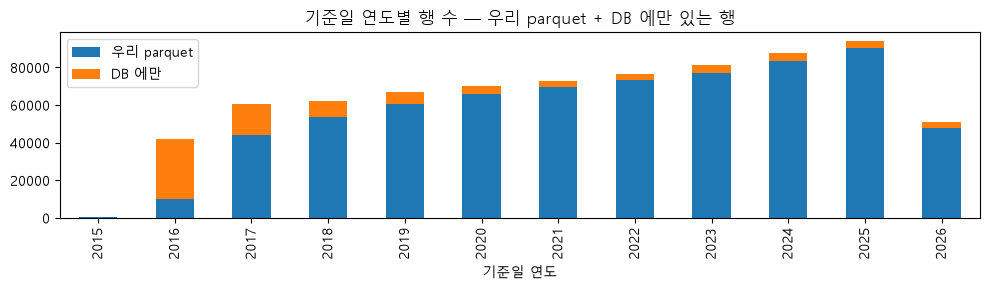

→ DB 에만 있는 행은 대부분 addr_source='검사기관'(시험실 주소라 제조 위치가 아님) 인 행이다. parquet 은 이 행을 뺀 것으로 보이므로 조인 기준은 parquet 로 둔다.


In [11]:
extra = body_db[~body_db['lims_data_key'].isin(pk)]
print(f"DB 에만 있는 {len(extra):,}행 — 주소 출처:", extra['addr_source'].value_counts().to_dict())
print('  경로:', extra['geo_route'].value_counts().to_dict(), '| 판정:', extra['judge_result'].value_counts().to_dict())
yr = pd.DataFrame({'우리 parquet': pq['mnfctur_de'].dt.year.value_counts(), 'DB 에만': extra['mnfctur_de_or_fallback'].dt.year.value_counts()}).fillna(0).astype(int).sort_index()
display(yr.T)
ax = yr.plot(kind='bar', stacked=True, figsize=(10, 3), title='기준일 연도별 행 수 — 우리 parquet + DB 에만 있는 행'); ax.set_xlabel('기준일 연도'); plt.tight_layout(); plt.show()
print("→ DB 에만 있는 행은 대부분 addr_source='검사기관'(시험실 주소라 제조 위치가 아님) 인 행이다. parquet 은 이 행을 뺀 것으로 보이므로 조인 기준은 parquet 로 둔다.")

### 3-3. 조인 기준 테이블 `base`
* 우리 parquet 676,537행에 DB 몸통 키 컬럼을 left join.
* `base_date` = parquet `mnfctur_de`. 좌표는 DB(double) 우선.
* 수입 건 국가(alpha-2) = 생산국 → 원산지 → 수입국 순.

In [12]:
KEYS = ['lims_data_key', 'prdlst_mnfctur_sttemnt_no', 'bsn_lcns_ledg_no', 'cntc_sys_key2', 'mapped_prdlst_code', 'prdlst_nm', 'statistic_prdlst_nm_1', 'statistic_prdlst_nm_2', 'statistic_prdlst_nm_3', 'statistic_prdlst_nm_4',
        'import_nation_code', 'prdctn_nation_code', 'orgplce_nation_code', 'reqest_de', 'inspct_begin_de', 'lat', 'lon', 'aw_grade', 'aw_match_level']
base = pq.merge(body_db[KEYS].rename(columns={'lat': 'lat_db', 'lon': 'lon_db'}), on='lims_data_key', how='left')
assert len(base) == len(pq) and base['lims_data_key'].is_unique
base['base_date'] = base['mnfctur_de']
base['base_year'] = base['base_date'].dt.year
base['lat_use'] = base['lat_db'].fillna(base['lat'].astype(float))
base['lon_use'] = base['lon_db'].fillna(base['lon'].astype(float))
base['nation_a2'] = base['prdctn_nation_code'].fillna(base['orgplce_nation_code']).fillna(base['import_nation_code'])
base['sgg_cd'] = base['legal_dong_code'].str[:5]
base['prdlst_code_use'] = base['mapped_prdlst_code'].fillna(base['prdlst_code'])
del cmp, extra; gc.collect()
print(f'base: {len(base):,}행 × {base.shape[1]}열')
display(nn_table(base, ['prdlst_mnfctur_sttemnt_no', 'bsn_lcns_ledg_no', 'cntc_sys_key2', 'mapped_prdlst_code', 'nation_a2', 'legal_dong_code', 'lat_use']))

base: 676,537행 × 48열


,컬럼,비결측%_domestic,비결측%_overseas,전체%
0,prdlst_mnfctur_sttemnt_no,32.5,0.0,30.2
1,bsn_lcns_ledg_no,29.4,0.0,27.3
2,cntc_sys_key2,5.6,99.6,12.2
3,mapped_prdlst_code,100.0,100.0,100.0
4,nation_a2,6.0,95.9,12.3
5,legal_dong_code,100.0,0.0,93.0
6,lat_use,100.0,100.0,100.0


## 4. 조인키 검증 — 수집 전에 키가 맞는지

후보가 둘 이상인 키는 매칭 수를 비교해 고른다. 모두 `SELECT` 이고, 키 목록은 파이썬에서 배열로 넘긴다(`= ANY(%s)`).

In [13]:
def uniq(s): return sorted(set(s.dropna().astype(str)))
k_lims = uniq(body_db['lims_data_key'])
print('4-1 lims_data_key ↔ ba_data.m_org_lims_data_info (PK)')
chk_m = query("SELECT COUNT(*) AS n_keys_matched FROM ba_data.m_org_lims_data_info WHERE lims_data_key = ANY(%s)", (uniq(pq['lims_data_key']),))
print(f"   parquet 키 {pq['lims_data_key'].nunique():,}개 중 m_org 에 있음 {chk_m.iloc[0, 0]:,}개 ({chk_m.iloc[0, 0] / pq['lims_data_key'].nunique():.2%})")

4-1 lims_data_key ↔ ba_data.m_org_lims_data_info (PK)


  (3.8초)


   parquet 키 676,537개 중 m_org 에 있음 669,334개 (98.94%)


In [14]:
print('4-2 품목제조번호: body.prdlst_mnfctur_sttemnt_no (원문 / 숫자만) ↔ t_prdlst_mnf_ledg.prdlst_report_no vs prdlst_report_ledg_no')
k_raw = uniq(base['prdlst_mnfctur_sttemnt_no'])
k_dig = sorted({re.sub(r'\D', '', k) for k in k_raw} - {''})
res = []
for col in ['prdlst_report_no', 'prdlst_report_ledg_no']:
    for nm, keys in [('원문', k_raw), ('숫자만', k_dig)]:
        n = query(f"SELECT COUNT(DISTINCT {col}) AS n FROM ba_data.t_prdlst_mnf_ledg WHERE {col} = ANY(%s)", (keys,)).iloc[0, 0]
        res.append({'대장 컬럼': col, '우리 키 형태': nm, '우리 고유 키': len(keys), '대장에서 찾은 키': n})
chk_l = pd.DataFrame(res); display(chk_l)
L_KEY = chk_l.groupby('대장 컬럼')['대장에서 찾은 키'].sum().idxmax()
print('→ 선택:', L_KEY)

4-2 품목제조번호: body.prdlst_mnfctur_sttemnt_no (원문 / 숫자만) ↔ t_prdlst_mnf_ledg.prdlst_report_no vs prdlst_report_ledg_no


  (0.6초)


  (0.6초)


  (0.5초)


  (0.5초)


,대장 컬럼,우리 키 형태,우리 고유 키,대장에서 찾은 키
0,prdlst_report_no,원문,35504,35089
1,prdlst_report_no,숫자만,35288,35153
2,prdlst_report_ledg_no,원문,35504,0
3,prdlst_report_ledg_no,숫자만,35288,0


→ 선택: prdlst_report_no


In [15]:
print('4-3 수입 접수번호: cntc_sys_key2 vs lims_data_key 2번째 토큰 ↔ s_org_lims_data_info.rcept_no')
ovs_keys = base.loc[base.src_route == 'overseas']
k_c2 = uniq(ovs_keys['cntc_sys_key2']); k_t2 = uniq(ovs_keys['lims_data_key'].str.split('_').str[1])
chk_s = pd.DataFrame([{'후보': 'cntc_sys_key2', '고유 키': len(k_c2), 's_org 에 있음': query("SELECT COUNT(DISTINCT rcept_no) FROM ba_data.s_org_lims_data_info WHERE rcept_no = ANY(%s)", (k_c2,)).iloc[0, 0]},
                      {'후보': 'lims_data_key 2번째 토큰', '고유 키': len(k_t2), 's_org 에 있음': query("SELECT COUNT(DISTINCT rcept_no) FROM ba_data.s_org_lims_data_info WHERE rcept_no = ANY(%s)", (k_t2,)).iloc[0, 0]}])
display(chk_s)
S_KEY = 'cntc_sys_key2' if chk_s.iloc[0, 2] >= chk_s.iloc[1, 2] else 'token2'
print('→ 선택:', S_KEY)
assert S_KEY == 'cntc_sys_key2', '토큰 키가 더 많이 맞음 — 5-2 수입 LIMS 조인 키를 바꿔야 함'

4-3 수입 접수번호: cntc_sys_key2 vs lims_data_key 2번째 토큰 ↔ s_org_lims_data_info.rcept_no


  (0.2초)
  (0.1초)


,후보,고유 키,s_org 에 있음
0,cntc_sys_key2,46155,46155
1,lims_data_key 2번째 토큰,40050,7101


→ 선택: cntc_sys_key2


In [16]:
print('4-4 영업허가번호 ↔ t_bsn_lcns_ledg')
k_bsn = uniq(base['bsn_lcns_ledg_no'])
n = query("SELECT COUNT(DISTINCT bsn_lcns_ledg_no) FROM ba_data.t_bsn_lcns_ledg WHERE bsn_lcns_ledg_no = ANY(%s)", (k_bsn,)).iloc[0, 0]
print(f'   고유 키 {len(k_bsn):,}개 중 {n:,}개 ({n / max(len(k_bsn), 1):.1%})')
print('4-5 공통코드 분류명: 정의서의 ZIM* vs 실제 IM*')
display(query("SELECT cmmn_cl_code, COUNT(*) AS n FROM ba_data.t_cm_cmmn_code WHERE cmmn_cl_code IN ('ZIM08','ZIM11','ZIM40','IM02','IM03','IM08','IM11','IM40') GROUP BY 1 ORDER BY 1").T)
print('4-6 관측소 ID: 관측소표 vs 일자료 보유')
display(query("""
SELECT 'ASOS 관측소표(이력 포함)' AS 구분, COUNT(*) AS 행, COUNT(DISTINCT stn_id) AS 고유 FROM api_data_info.kma_ground_obs_station_info
UNION ALL SELECT 'ASOS 일자료', COUNT(*), COUNT(DISTINCT stn_id) FROM api_data_info.kma_asos_daily_info
UNION ALL SELECT 'NAS 관측소표', COUNT(*), COUNT(DISTINCT obsr_spot_code) FROM api_data_info.nas_agri_weather_obs_station
UNION ALL SELECT 'NAS 일자료', COUNT(*), COUNT(DISTINCT obsr_spot_code) FROM api_data_info.nas_agri_weather_daily_info
UNION ALL SELECT '에어코리아 측정소표', COUNT(*), COUNT(DISTINCT station_nm) FROM api_data_info.keco_airkorea_obs_station
UNION ALL SELECT '에어코리아 일자료', COUNT(*), COUNT(DISTINCT station_nm) FROM api_data_info.keco_airkorea_fine_dust_info"""))

4-4 영업허가번호 ↔ t_bsn_lcns_ledg


  (0.1초)
   고유 키 5,068개 중 5,068개 (100.0%)
4-5 공통코드 분류명: 정의서의 ZIM* vs 실제 IM*


  (0.0초)


,0,1,2,3,4
cmmn_cl_code,IM02,IM03,IM08,IM11,IM40
n,15,17,5,7,4


4-6 관측소 ID: 관측소표 vs 일자료 보유


  (0.4초)


,구분,행,고유
0,NAS 관측소표,219,219
1,ASOS 관측소표(이력 포함),243,105
2,에어코리아 측정소표,753,673
3,NAS 일자료,984648,219
4,ASOS 일자료,406909,99
5,에어코리아 일자료,2150630,691


In [17]:
print('4-7 에어코리아 측정소 좌표: 정의서는 dm_x/dm_y = "TM 좌표" 라고 적었지만 실제 값 범위는?')
display(query("SELECT MIN(dm_x) AS dm_x_min, MAX(dm_x) AS dm_x_max, MIN(dm_y) AS dm_y_min, MAX(dm_y) AS dm_y_max, COUNT(*) AS n FROM api_data_info.keco_airkorea_obs_station"))
print('   → dm_x 33~39, dm_y 124~131 : 이미 위도(dm_x)·경도(dm_y). TM 변환을 하면 오히려 좌표가 망가진다 (매핑 시트1·6 의 "TM→위경도 변환" 은 불필요).')
print('4-8 국가코드: 몸통은 alpha-2(US, IT…) / 해외 기상은 alpha-3 → 변환표 ba_data_info.nation_code (정의서 밖 코드표, 읽기만)')
display(query("SELECT alpha_2, alpha_3, nation_code FROM ba_data_info.nation_code WHERE alpha_2 IN ('US','IT','FR','VN','CN') ORDER BY 1"))

4-7 에어코리아 측정소 좌표: 정의서는 dm_x/dm_y = "TM 좌표" 라고 적었지만 실제 값 범위는?
  (0.0초)


,dm_x_min,dm_x_max,dm_y_min,dm_y_max,n
0,33.227749,38.563209,124.645669,130.904047,753


   → dm_x 33~39, dm_y 124~131 : 이미 위도(dm_x)·경도(dm_y). TM 변환을 하면 오히려 좌표가 망가진다 (매핑 시트1·6 의 "TM→위경도 변환" 은 불필요).
4-8 국가코드: 몸통은 alpha-2(US, IT…) / 해외 기상은 alpha-3 → 변환표 ba_data_info.nation_code (정의서 밖 코드표, 읽기만)
  (0.0초)


,alpha_2,alpha_3,nation_code
0,CN,CHN,156
1,FR,FRA,250
2,IT,ITA,380
3,US,USA,840
4,VN,VNM,704


## 5. DB 수집 + 상태 확인

### 5-1. 행 단위 속성 — 식약처 LIMS 원본 (`ba_data.m_org_lims_data_info`)
운반 상태 온도·방법, 시료 상태(= 저장·유통 온도 대체), 접수·검사완료일, 유통일, 상위 품목. 2.ipynb 에서 검출과 강하게 얽힌 것으로 확인된 **검사목적·검사종류 코드**도 참고용으로 같이 받는다(매핑 외).

In [18]:
m_org = collect('02a_m_org', """
SELECT h.lims_data_key,
       m.cnvync_sttus_tp, m.cnvync_sttus_tp_unit_code, m.cnvync_mth_code, m.splore_sttus_code,
       m.distb_de, m.valid_tmlmt, m.pick_de, m.rcept_de, m.inspct_end_de,
       m.upper_prdlst_code, m.upper_prdlst_nm, m.expr_se_nm,
       m.inspct_purps_code, m.inspct_knd_code
FROM ready_data.hazard_preprocessed_data h
JOIN ba_data.m_org_lims_data_info m ON m.lims_data_key = h.lims_data_key
WHERE h.hazard_label = '리스테리아'""", source='ba_data.m_org_lims_data_info')
codes = collect('70_codes', "SELECT cmmn_cl_code, cmmn_code, cmmn_code_nm FROM ba_data.t_cm_cmmn_code WHERE cmmn_cl_code IN ('IM02','IM03','IM08','IM11','IM40') ORDER BY 1, 2",
                source='ba_data.t_cm_cmmn_code (IM02·IM03·IM08·IM11·IM40)')
CODE = {cl: dict(zip(g['cmmn_code'], g['cmmn_code_nm'])) for cl, g in codes.groupby('cmmn_cl_code')}
m_org['cnvync_tp_unit_nm'] = m_org['cnvync_sttus_tp_unit_code'].map(CODE['IM40'])
m_org['cnvync_mth_nm'] = m_org['cnvync_mth_code'].map(CODE['IM08'])
m_org['splore_sttus_nm'] = m_org['splore_sttus_code'].map(CODE['IM11'])
m_org['inspct_purps_nm'] = m_org['inspct_purps_code'].map(CODE['IM02'])
m_org['inspct_knd_nm'] = m_org['inspct_knd_code'].map(CODE['IM03'])
assert m_org['lims_data_key'].is_unique

[02a_m_org] 캐시: 758,574행 × 15열 (0초) ← ba_data.m_org_lims_data_info
[70_codes] 캐시: 48행 × 3열 (0초) ← ba_data.t_cm_cmmn_code (IM02·IM03·IM08·IM11·IM40)


### 5-2. 품목제조대장 · 영업허가대장 · 식품공전 분류 · 수입 LIMS · 해외제조업소

In [19]:
ledg_raw = collect('02b_ledg', f"""
SELECT prdlst_report_no, prdlst_report_ledg_no, prdlst_cd, prdlst_nm, prms_dt, end_dt, del_yn, last_updt_dtm,
       mnf_cnd_cn, prsrv_distb_stdr_cn, pog_daycnt, qlity_mntnc_tmlmt_daycnt, frmlc_mtrqlt, haccp_appn_no
FROM ba_data.t_prdlst_mnf_ledg WHERE {L_KEY} = ANY(%s)""", (sorted(set(k_raw) | set(k_dig)),), source=f'ba_data.t_prdlst_mnf_ledg ({L_KEY} = 원문·숫자만 키)')
bsn = collect('02c_bsn', "SELECT bsn_lcns_ledg_no, domini_sort, fish_sort, wrkshp_pkrm_area FROM ba_data.t_bsn_lcns_ledg WHERE bsn_lcns_ledg_no = ANY(%s)",
              (k_bsn,), source='ba_data.t_bsn_lcns_ledg')
cl = collect('02d_cl', "SELECT prdlst_cd, lv, hrnk_prdlst_cd, htrk_prdlst_cd, fdgrp_yn, artcl_gun_code, food_hf_ls_cl_cd, dfn, use_yn FROM ba_data.t_prdlst_cl",
             source='ba_data.t_prdlst_cl (전체)')
k_s = uniq(base['cntc_sys_key2'])
s_org_raw = collect('02e_s_org', """
SELECT rcept_no, label, lims_seq, mnf_nation_cd, shipng_de, entrpt_de, wrhous_carry_de, bonded_area_cd, wrhous_cd, custom_cd, inspct_carry_plc, impt_ownr_induty,
       distb_bgn_de, distb_end_de, prduct_dvs_cd, dclr_prduct_dvs, hsk_no, packng_plc_cd, ovsmnfst_cd
FROM ba_data.s_org_lims_data_info WHERE rcept_no = ANY(%s)""", (k_s,), source='ba_data.s_org_lims_data_info (rcept_no = cntc_sys_key2)')
co = collect('02f_co', "SELECT ovsmnfst_cd, sfrprp_food_se_cd, sfrprp_regist_fclty_no FROM ba_data.s_co_ifd_ovsmnfst_regstr_m WHERE ovsmnfst_cd = ANY(%s)",
             (uniq(s_org_raw['ovsmnfst_cd']),), source='ba_data.s_co_ifd_ovsmnfst_regstr_m')

[02b_ledg] 캐시: 35,873행 × 14열 (0초) ← ba_data.t_prdlst_mnf_ledg (prdlst_report_no = 원문·숫자만 키)
[02c_bsn] 캐시: 5,068행 × 4열 (0초) ← ba_data.t_bsn_lcns_ledg
[02d_cl] 캐시: 8,864행 × 9열 (0초) ← ba_data.t_prdlst_cl (전체)
[02e_s_org] 캐시: 202,219행 × 19열 (0초) ← ba_data.s_org_lims_data_info (rcept_no = cntc_sys_key2)


[02f_co] 캐시: 1,124행 × 3열 (0초) ← ba_data.s_co_ifd_ovsmnfst_regstr_m


In [20]:
# 키당 1행으로 정리 (중복 규칙을 명시)
ledg = (ledg_raw.assign(_live=(ledg_raw['del_yn'].fillna('N') == 'N'))
        .sort_values([L_KEY, '_live', 'last_updt_dtm'], ascending=[True, False, False])
        .drop_duplicates(L_KEY).drop(columns='_live'))
s_org = (s_org_raw.assign(_lis=(s_org_raw['label'] == '리스테리아'))
         .sort_values(['rcept_no', '_lis', 'lims_seq'], ascending=[True, False, True]).drop_duplicates('rcept_no').drop(columns=['_lis', 'label', 'lims_seq']))
co1 = co.drop_duplicates('ovsmnfst_cd')
cl1 = cl.assign(_u=(cl['use_yn'].fillna('Y') == 'Y')).sort_values(['prdlst_cd', '_u'], ascending=[True, False]).drop_duplicates('prdlst_cd').drop(columns=['_u', 'use_yn'])
dup = pd.DataFrame([('품목제조대장', len(ledg_raw), len(ledg)), ('수입 LIMS', len(s_org_raw), len(s_org)), ('해외제조업소', len(co), len(co1)), ('식품공전 분류', len(cl), len(cl1))],
                   columns=['원천', '받은 행', '키당 1행 정리 후'])
display(dup)

,원천,받은 행,키당 1행 정리 후
0,품목제조대장,35873,35153
1,수입 LIMS,202219,46164
2,해외제조업소,1124,1124
3,식품공전 분류,8864,8864


### 5-3. 국내 기상 — 관측소표 + ASOS·NAS 일자료
* 후보 관측소는 **일자료를 실제 보유한 곳만**. ASOS 관측소표는 같은 `stn_id` 가 이력별로 여러 행이라 1행만 남긴다(예보구역 코드 있는 최신 행).
* 일자료는 (최소 기준일 − 30일) ~ 최대 기준일. 일조(`sum_sshr`, `sun_time`)는 text 라 숫자로 캐스팅.

In [21]:
d0 = (base['base_date'].min() - pd.Timedelta(days=30)).date(); d1 = base['base_date'].max().date()
print('일자료 기간:', d0, '~', d1)
asos_stn = collect('31_asos_station', """
SELECT DISTINCT ON (st.stn_id) st.stn_id, st.stn_ko, st.lat::float8 AS lat, st.lon::float8 AS lon, st.ht, st.basin, st.fct_id, st.legaldong_code
FROM api_data_info.kma_ground_obs_station_info st
WHERE st.stn_id IN (SELECT DISTINCT stn_id FROM api_data_info.kma_asos_daily_info)
ORDER BY st.stn_id, (st.fct_id IS NOT NULL) DESC, st.chg_dt DESC NULLS LAST""", source='api_data_info.kma_ground_obs_station_info')
nas_stn = collect('31_nas_station', """
SELECT DISTINCT ON (st.obsr_spot_code) st.obsr_spot_code, st.obsr_spot_nm, st.instl_la::float8 AS lat, st.instl_lo::float8 AS lon, st.instl_al, st.clmt_zone_code, st.legaldong_code
FROM api_data_info.nas_agri_weather_obs_station st
WHERE st.obsr_spot_code IN (SELECT DISTINCT obsr_spot_code FROM api_data_info.nas_agri_weather_daily_info)
ORDER BY st.obsr_spot_code, (st.use_yn = '1') DESC, st.chg_dt DESC NULLS LAST""", source='api_data_info.nas_agri_weather_obs_station')
NUM = r"~ '^\s*-?[0-9]+(\.[0-9]+)?\s*$'"
asos = collect('32_asos_daily', f"""
SELECT stn_id, meas_date, avg_ta, max_ta, min_ta, sum_rn, avg_ws, max_ws, max_ins_ws,
       CASE WHEN sum_sshr {NUM} THEN sum_sshr::float8 END AS sum_sshr_num, sum_gsr,
       avg_ts, min_tg, avg_cm5_te, avg_cm10_te, avg_cm20_tes, avg_cm30_te
FROM api_data_info.kma_asos_daily_info WHERE meas_date BETWEEN %(d0)s AND %(d1)s""", {'d0': d0, 'd1': d1}, source='api_data_info.kma_asos_daily_info')
nas = collect('33_nas_daily', f"""
SELECT obsr_spot_code, meas_date, temp, hghst_artmp, lowst_artmp, rn, wind, max_wind,
       CASE WHEN sun_time {NUM} THEN sun_time::float8 END AS sun_time_num, srqty, gr_temp, soil_temp, soil_wt
FROM api_data_info.nas_agri_weather_daily_info WHERE meas_date BETWEEN %(d0)s AND %(d1)s""", {'d0': d0, 'd1': d1}, source='api_data_info.nas_agri_weather_daily_info')

일자료 기간: 2015-03-08 ~ 2026-06-30
[31_asos_station] 캐시: 99행 × 8열 (0초) ← api_data_info.kma_ground_obs_station_info
[31_nas_station] 캐시: 219행 × 7열 (0초) ← api_data_info.nas_agri_weather_obs_station
[32_asos_daily] 캐시: 394,400행 × 17열 (0초) ← api_data_info.kma_asos_daily_info
[33_nas_daily] 캐시: 813,882행 × 13열 (0초) ← api_data_info.nas_agri_weather_daily_info


In [22]:
def daily_status(df, id_col, date_col, cols, name):
    print(f"■ {name}: {len(df):,}행, 지점 {df[id_col].nunique()}개, {pd.to_datetime(df[date_col]).min():%Y-%m-%d} ~ {pd.to_datetime(df[date_col]).max():%Y-%m-%d}, (지점,일) 중복 {df.duplicated([id_col, date_col]).sum()}")
    display(pd.DataFrame({'컬럼': cols, '비결측%': [round(df[c].notna().mean() * 100, 1) for c in cols],
                          '값 보유 지점': [df.loc[df[c].notna(), id_col].nunique() for c in cols],
                          '중앙값': [round(float(df[c].median()), 2) if df[c].notna().any() else np.nan for c in cols],
                          '최소': [round(float(df[c].min()), 2) if df[c].notna().any() else np.nan for c in cols],
                          '최대': [round(float(df[c].max()), 2) if df[c].notna().any() else np.nan for c in cols]}).set_index('컬럼').T)
daily_status(asos, 'stn_id', 'meas_date', ['avg_ta', 'max_ta', 'min_ta', 'sum_rn', 'avg_ws', 'sum_sshr_num', 'sum_gsr', 'avg_ts', 'avg_cm5_te', 'avg_cm10_te', 'avg_cm20_tes'], 'ASOS 일자료')
daily_status(nas, 'obsr_spot_code', 'meas_date', ['temp', 'hghst_artmp', 'lowst_artmp', 'rn', 'wind', 'sun_time_num', 'srqty', 'gr_temp', 'soil_temp', 'soil_wt'], 'NAS 농업기상 일자료')

■ ASOS 일자료: 394,400행, 지점 99개, 2015-03-08 ~ 2026-06-30, (지점,일) 중복 0


컬럼,avg_ta,max_ta,min_ta,sum_rn,avg_ws,sum_sshr_num,sum_gsr,avg_ts,avg_cm5_te,avg_cm10_te,avg_cm20_tes
비결측%,99.9,100.0,100.0,37.6,99.8,99.7,50.90,99.9,29.1,29.1,29.1
값 보유 지점,99.0,99.0,99.0,99.0,99.0,99.0,77.00,99.0,29.0,29.0,29.0
중앙값,14.5,20.4,9.2,1.6,1.6,7.2,13.67,16.5,16.3,16.3,16.3
최소,-19.7,-15.2,-25.2,0.0,0.0,0.0,0.00,-14.9,-8.3,-7.0,-5.2
최대,34.1,41.0,30.6,438.9,22.3,14.2,45.38,43.8,38.5,37.1,35.7


■ NAS 농업기상 일자료: 813,882행, 지점 219개, 2015-03-08 ~ 2026-06-30, (지점,일) 중복 0


컬럼,temp,hghst_artmp,lowst_artmp,rn,wind,sun_time_num,srqty,gr_temp,soil_temp,soil_wt
비결측%,88.2,88.2,88.2,92.4,80.1,31.1,79.2,43.1,12.6,53.3
값 보유 지점,195.0,195.0,196.0,203.0,182.0,91.0,180.0,106.0,44.0,150.0
중앙값,13.7,20.4,7.6,0.0,0.8,422.0,13.4,14.0,15.4,22.8
최소,-49.4,-50.0,-50.0,0.0,0.0,0.0,0.0,-49.5,-39.4,-36.2
최대,49.5,50.0,50.0,500.0,37.3,1200.0,40.0,90.0,48.1,50.0


### 5-3b. 기상 일자료 품질 점검 (QC) — 창 집계 전에 적용
* **ASOS 강수 `sum_rn`**: 비가 안 온 날이 0 이 아니라 **빈 값**으로 저장된다(비결측 약 38%). 그날 기온 관측이 있으면 강수 결측 = 0 으로 채운다.
* **NAS**: 기온·토양수분 등에 ±50 같은 **경계값(센서 오류 추정)** 이 있다. 물리적으로 불가능한 범위는 결측 처리한다.
* **NAS 일조 `sun_time`**: 중앙값 약 422 → **분 단위**로 보인다(ASOS 일조 중앙값 7.2시간 ≈ 432분). 시간으로 바꾸고 15시간 초과는 결측.

In [23]:
qc = []
def qc_range(df, col, lo, hi, name):
    bad = df[col].notna() & ~df[col].between(lo, hi)
    qc.append({'자료': name, '컬럼': col, '규칙': f'{lo} ~ {hi} 밖은 결측', '해당 행': int(bad.sum()), '비율%': round(bad.mean() * 100, 3)})
    df.loc[bad, col] = np.nan

n_fill = int((asos['sum_rn'].isna() & asos['avg_ta'].notna()).sum())
asos['sum_rn'] = asos['sum_rn'].where(asos['sum_rn'].notna() | asos['avg_ta'].isna(), 0.0)
qc.append({'자료': 'ASOS', '컬럼': 'sum_rn', '규칙': '기온 관측일의 결측 → 0', '해당 행': n_fill, '비율%': round(n_fill / len(asos) * 100, 1)})
for c in ['avg_ta', 'max_ta', 'min_ta']: qc_range(asos, c, -35, 45, 'ASOS')
qc_range(asos, 'sum_sshr_num', 0, 15, 'ASOS')
nas['sun_time_num'] = nas['sun_time_num'] / 60.0
qc.append({'자료': 'NAS', '컬럼': 'sun_time_num', '규칙': '분 → 시간 (/60)', '해당 행': int(nas['sun_time_num'].notna().sum()), '비율%': np.nan})
for c in ['temp', 'hghst_artmp', 'lowst_artmp']: qc_range(nas, c, -35, 45, 'NAS')
qc_range(nas, 'gr_temp', -35, 70, 'NAS'); qc_range(nas, 'soil_temp', -30, 45, 'NAS')
qc_range(nas, 'soil_wt', 0, 60, 'NAS'); qc_range(nas, 'rn', 0, 499, 'NAS'); qc_range(nas, 'sun_time_num', 0, 15, 'NAS')
display(pd.DataFrame(qc))

,자료,컬럼,규칙,해당 행,비율%
0,ASOS,sum_rn,기온 관측일의 결측 → 0,245708,62.300
1,ASOS,avg_ta,-35 ~ 45 밖은 결측,0,0.000
2,ASOS,max_ta,-35 ~ 45 밖은 결측,0,0.000
3,ASOS,min_ta,-35 ~ 45 밖은 결측,0,0.000
4,ASOS,sum_sshr_num,0 ~ 15 밖은 결측,0,0.000
5,NAS,sun_time_num,분 → 시간 (/60),252931,NaN
6,NAS,temp,-35 ~ 45 밖은 결측,25,0.003
7,NAS,hghst_artmp,-35 ~ 45 밖은 결측,109,0.013
8,NAS,lowst_artmp,-35 ~ 45 밖은 결측,155,0.019
9,NAS,gr_temp,-35 ~ 70 밖은 결측,172,0.021


### 5-4. 토양 pH — 법정동 × 조사연도 집계 (+ 시군구, 해외 국가별)
`soil_ph_info` 는 필지 단위 약 628만 행이라 DB 에서 **집계해서** 받는다. `any_year` 는 `character(4)` 라 정수로 캐스팅. 토양 pH 로 불가능한 값이 섞여 있어(법정동 평균 최대 30 이상) **pH 3~10 인 필지만** 집계한다.

In [24]:
soil_dong = collect('41_soil_dong_year_qc', """
SELECT legal_dong_code, NULLIF(TRIM(any_year), '')::int AS yr, COUNT(*) AS n_samples,
       AVG(acid)::float8 AS soil_ph_mean, STDDEV(acid)::float8 AS soil_ph_std, AVG(vldpha)::float8 AS vldpha_mean, AVG(om)::float8 AS om_mean
FROM api_data_info.soil_ph_info WHERE acid BETWEEN 3 AND 10 GROUP BY legal_dong_code, any_year""", source='api_data_info.soil_ph_info (법정동×연도 집계, pH 3~10)')
soil_sgg = collect('42_soil_sgg_year_qc', """
SELECT LEFT(legal_dong_code, 5) AS sgg_cd, NULLIF(TRIM(any_year), '')::int AS yr, COUNT(*) AS n_samples,
       AVG(acid)::float8 AS soil_ph_mean, AVG(vldpha)::float8 AS vldpha_mean, AVG(om)::float8 AS om_mean
FROM api_data_info.soil_ph_info WHERE acid BETWEEN 3 AND 10 GROUP BY LEFT(legal_dong_code, 5), any_year""", source='api_data_info.soil_ph_info (시군구×연도 집계, pH 3~10)')
print('pH 범위 밖 필지 수:'); display(query("SELECT COUNT(*) FILTER (WHERE acid < 3) AS ph_lt3, COUNT(*) FILTER (WHERE acid > 10) AS ph_gt10, COUNT(acid) AS n_acid FROM api_data_info.soil_ph_info"))
soil_global = collect('43_global_soil_ph', "SELECT iso3, nation_code, name_ko, sub_region, ph_mean, ph_std FROM api_data_info.global_soil_ph", source='api_data_info.global_soil_ph')
print(f"법정동 {soil_dong['legal_dong_code'].nunique():,}개 · 연도 {soil_dong['yr'].min()}~{soil_dong['yr'].max()} | 시군구 {soil_sgg['sgg_cd'].nunique()}개 | 해외 {soil_global['iso3'].nunique()}개국 (pH 보유 {soil_global['ph_mean'].notna().sum()})")
display(soil_dong[['n_samples', 'soil_ph_mean', 'vldpha_mean', 'om_mean']].describe().T[['count', 'mean', '50%', 'min', 'max']])

[41_soil_dong_year_qc] 캐시: 179,594행 × 7열 (0초) ← api_data_info.soil_ph_info (법정동×연도 집계, pH 3~10)
[42_soil_sgg_year_qc] 캐시: 2,813행 × 6열 (0초) ← api_data_info.soil_ph_info (시군구×연도 집계, pH 3~10)
pH 범위 밖 필지 수:


  (0.3초)


,ph_lt3,ph_gt10,n_acid
0,51,138,6184118


[43_global_soil_ph] 캐시: 235행 × 6열 (0초) ← api_data_info.global_soil_ph
법정동 17,422개 · 연도 2015~2026 | 시군구 251개 | 해외 235개국 (pH 보유 228)


,count,mean,50%,min,max
n_samples,179594.0,34.432826,16.000000,1.0,2766.00
soil_ph_mean,179594.0,6.310026,6.292308,3.3,9.80
vldpha_mean,179508.0,356.583974,293.000000,0.0,5962.25
om_mean,179509.0,25.745604,23.775000,0.0,333.25


### 5-5. 대기 — 에어코리아 측정소 + 일자료 (NO2·CO·SO2)

In [25]:
air_stn = collect('50_air_station', """
SELECT DISTINCT ON (station_nm) station_nm, dm_x::float8 AS lat, dm_y::float8 AS lon, legaldong_code, mang_name, use_yn
FROM api_data_info.keco_airkorea_obs_station WHERE dm_x IS NOT NULL AND dm_y IS NOT NULL
ORDER BY station_nm, (use_yn = '1') DESC, chg_dt DESC NULLS LAST""", source='api_data_info.keco_airkorea_obs_station (dm_x=위도, dm_y=경도)')
air = collect('50_air_daily', "SELECT station_nm, msur_dt, no2_value, co_value, so2_value FROM api_data_info.keco_airkorea_fine_dust_info WHERE msur_dt BETWEEN %(d0)s AND %(d1)s",
              {'d0': d0, 'd1': d1}, source='api_data_info.keco_airkorea_fine_dust_info')
print(f"일자료 측정소 {air['station_nm'].nunique()}개 중 좌표 있는 측정소표에 있는 곳 {air['station_nm'].drop_duplicates().isin(air_stn['station_nm']).sum()}개")
air = air[air['station_nm'].isin(air_stn['station_nm'])]
daily_status(air, 'station_nm', 'msur_dt', ['no2_value', 'co_value', 'so2_value'], '에어코리아 일자료')

[50_air_station] 캐시: 673행 × 6열 (0초) ← api_data_info.keco_airkorea_obs_station (dm_x=위도, dm_y=경도)
[50_air_daily] 캐시: 2,112,356행 × 5열 (0초) ← api_data_info.keco_airkorea_fine_dust_info
일자료 측정소 691개 중 좌표 있는 측정소표에 있는 곳 672개


■ 에어코리아 일자료: 2,075,354행, 지점 672개, 2015-03-08 ~ 2026-06-30, (지점,일) 중복 0


컬럼,no2_value,co_value,so2_value
비결측%,97.90,97.10,97.3
값 보유 지점,670.00,669.00,669.0
중앙값,0.01,0.40,0.0
최소,0.00,0.00,0.0
최대,0.17,3.87,0.5


### 5-6. 해외 기상 (수입 건) — 국가 × 일 + 국가코드 변환표
`global_weather_info` 는 테이블목록에 **'재수집 대상, 현재 미사용'**(국가당 1점) 으로 표시돼 있다. 한계를 알고 붙인다.

In [26]:
ovs = base['src_route'] == 'overseas'
od0 = (base.loc[ovs, 'base_date'].min() - pd.Timedelta(days=30)).date(); od1 = base.loc[ovs, 'base_date'].max().date()
gw = collect('60_global_daily', """
SELECT alpha_3, date, temperature_mean, temperature_max, temperature_min, precipitation_sum, relative_humidity_mean,
       soil_moisture_mean, sunshine_duration, wind_speed_mean, shortwave_radiation_sum
FROM api_data_info.global_weather_info WHERE date BETWEEN %(d0)s AND %(d1)s""", {'d0': od0, 'd1': od1}, source='api_data_info.global_weather_info')
nation = collect('61_nation_code', "SELECT alpha_2, alpha_3, nation_code FROM ba_data_info.nation_code", source='ba_data_info.nation_code')
daily_status(gw, 'alpha_3', 'date', ['temperature_mean', 'precipitation_sum', 'relative_humidity_mean', 'soil_moisture_mean', 'sunshine_duration', 'wind_speed_mean', 'shortwave_radiation_sum'], '해외 국가별 일자료')
gw['sunshine_duration'] = gw['sunshine_duration'] / 3600.0   # 초 → 시간 (중앙값 약 39,000초 = 10.9시간)
print('※ 해외 일조 sunshine_duration 은 초 단위라 시간으로 변환했다. 풍속은 km/h 로 보인다(중앙값 10.8).')
A2A3 = dict(zip(nation['alpha_2'].str.strip(), nation['alpha_3'].str.strip()))
a2 = base.loc[ovs, 'nation_a2']
print(f"수입 건 국가코드 보유 {a2.notna().mean():.1%} → alpha-3 변환 {a2.dropna().map(A2A3).notna().mean():.1%} → 해외 기상에 국가 있음 {a2.dropna().map(A2A3).isin(gw['alpha_3']).mean():.1%}")

[60_global_daily] 캐시: 1,015,671행 × 11열 (0초) ← api_data_info.global_weather_info
[61_nation_code] 캐시: 249행 × 3열 (0초) ← ba_data_info.nation_code
■ 해외 국가별 일자료: 1,015,671행, 지점 249개, 2015-04-21 ~ 2026-06-20, (지점,일) 중복 0


컬럼,temperature_mean,precipitation_sum,relative_humidity_mean,soil_moisture_mean,sunshine_duration,wind_speed_mean,shortwave_radiation_sum
비결측%,100.0,100.0,100.0,100.00,100.00,100.0,100.00
값 보유 지점,249.0,249.0,249.0,249.00,249.00,249.0,249.00
중앙값,23.4,0.4,77.0,0.23,39207.42,10.8,18.83
최소,-68.6,0.0,3.0,-0.00,0.00,0.3,0.00
최대,43.8,527.2,100.0,0.76,86392.26,96.0,41.43


※ 해외 일조 sunshine_duration 은 초 단위라 시간으로 변환했다. 풍속은 km/h 로 보인다(중앙값 10.8).


수입 건 국가코드 보유 95.9% → alpha-3 변환 99.7% → 해외 기상에 국가 있음 99.7%


### 5-7. 수집 로그

In [27]:
log_df = pd.DataFrame(LOG); display(log_df)
print(f"파일 {len(log_df)}개, 총 {log_df['행'].sum():,}행, {log_df['초'].sum()}초 (DB 에서 받은 파일 {(log_df['방식'] == 'DB').sum()}개)")

,파일,DB 원천,방식,행,열,초
0,00_body_db.parquet,ready_data.hazard_preprocessed_data,DB,765891,28,8
1,02a_m_org.parquet,ba_data.m_org_lims_data_info,캐시,758574,15,0
2,70_codes.parquet,ba_data.t_cm_cmmn_code (IM02·IM03·IM08·IM11·IM40),캐시,48,3,0
3,02b_ledg.parquet,ba_data.t_prdlst_mnf_ledg (prdlst_report_no = 원문·숫자만 키),캐시,35873,14,0
4,02c_bsn.parquet,ba_data.t_bsn_lcns_ledg,캐시,5068,4,0
5,02d_cl.parquet,ba_data.t_prdlst_cl (전체),캐시,8864,9,0
6,02e_s_org.parquet,ba_data.s_org_lims_data_info (rcept_no = cntc_sys_key2),캐시,202219,19,0
7,02f_co.parquet,ba_data.s_co_ifd_ovsmnfst_regstr_m,캐시,1124,3,0
8,31_asos_station.parquet,api_data_info.kma_ground_obs_station_info,캐시,99,8,0
9,31_nas_station.parquet,api_data_info.nas_agri_weather_obs_station,캐시,219,7,0


파일 19개, 총 6,297,852행, 8초 (DB 에서 받은 파일 1개)


## 6. 조인

(1) 행 단위 속성 → (2) 최근접 관측소 → (3) 기준일 창 D0·7일·30일 → (4) 토양 pH → (5) 대기 → (6) 해외. 매 단계 행 수가 676,537 인지 `assert`.

### 6-1. 행 단위 속성 조인 + 간단한 파생

In [28]:
J = base.merge(m_org, on='lims_data_key', how='left')
# 품목제조대장: 원문 키로 먼저, 안 붙은 행은 숫자만 키로
J['_k_raw'] = J['prdlst_mnfctur_sttemnt_no']
J['_k_dig'] = J['prdlst_mnfctur_sttemnt_no'].str.replace(r'\D', '', regex=True)
LEDG_COLS = ['mnf_cnd_cn', 'prsrv_distb_stdr_cn', 'pog_daycnt', 'qlity_mntnc_tmlmt_daycnt', 'frmlc_mtrqlt', 'haccp_appn_no']
lk = ledg.set_index(L_KEY)[LEDG_COLS]
hit_raw = J['_k_raw'].isin(lk.index); hit_dig = ~hit_raw & J['_k_dig'].isin(lk.index)
for c in LEDG_COLS:
    J[c] = None
J.loc[hit_raw, LEDG_COLS] = lk.loc[J.loc[hit_raw, '_k_raw'], LEDG_COLS].to_numpy()
J.loc[hit_dig, LEDG_COLS] = lk.loc[J.loc[hit_dig, '_k_dig'], LEDG_COLS].to_numpy()
J['ledg_match'] = pd.Series(np.where(hit_raw, '원문', np.where(hit_dig, '숫자만', '')), index=J.index).replace('', None)
print('품목제조대장 매칭:', J['ledg_match'].value_counts(dropna=False).to_dict())
J = J.merge(bsn.drop_duplicates('bsn_lcns_ledg_no'), on='bsn_lcns_ledg_no', how='left')
J = J.merge(cl1.rename(columns={'prdlst_cd': 'prdlst_code_use', 'prdlst_nm': 'cl_prdlst_nm', 'lv': 'cl_lv', 'dfn': 'cl_dfn'}), on='prdlst_code_use', how='left')
J = J.merge(s_org.rename(columns={'rcept_no': 'cntc_sys_key2'}), on='cntc_sys_key2', how='left')
J = J.merge(co1, on='ovsmnfst_cd', how='left')
J = J.drop(columns=['_k_raw', '_k_dig'])
assert len(J) == len(base) and J['lims_data_key'].is_unique
print(f'J: {len(J):,}행 × {J.shape[1]}열')

품목제조대장 매칭: {nan: 473041, '원문': 202926, '숫자만': 570}


J: 676,537행 × 102열


In [29]:
for c in ['distb_de', 'pick_de', 'rcept_de', 'inspct_end_de', 'shipng_de', 'entrpt_de', 'wrhous_carry_de', 'distb_bgn_de', 'distb_end_de']:
    J[c] = pd.to_datetime(J[c], errors='coerce')

def shelf_days(t):
    """'제조일로부터 12개월' → 365, '30일' → 30, '1년' → 365 (첫 숫자+단위만)"""
    if not isinstance(t, str): return np.nan
    m = re.search(r'(\d+(?:\.\d+)?)\s*(일|개월|달|월|년)', t)
    if not m: return np.nan
    v, u = float(m.group(1)), m.group(2)
    return v if u == '일' else v * 30.4 if u in ('개월', '달', '월') else v * 365

J['shelf_life_days'] = J['pog_daycnt'].map(shelf_days)
J['days_mnf_to_rcept'] = (J['rcept_de'] - J['base_date']).dt.days.where(J['date_basis'] == '제조일')     # 제조 → 접수(의뢰)
J['days_rcept_to_end'] = (J['inspct_end_de'] - J['rcept_de']).dt.days                                   # 접수 → 검사완료
J['days_base_to_distb'] = (J['distb_de'] - J['base_date']).dt.days                                       # distb_de 는 유통기한 날짜로 보임(2.ipynb)
txt = J['prsrv_distb_stdr_cn'].fillna('') + ' ' + J['mnf_cnd_cn'].fillna('') + ' ' + J['pog_daycnt'].fillna('')
has_txt = txt.str.strip() != ''
J['flag_refrig'] = txt.str.contains('냉장').astype(float).where(has_txt)
J['flag_frozen'] = txt.str.contains('냉동').astype(float).where(has_txt)
J['flag_steril'] = txt.str.contains('살균|멸균').astype(float).where(has_txt)
J['flag_vacuum'] = J['frmlc_mtrqlt'].fillna('').str.contains('진공').astype(float).where(J['frmlc_mtrqlt'].notna())
J['days_ship_to_entry'] = (J['entrpt_de'] - J['shipng_de']).dt.days
J['days_entry_to_rcept'] = (J['rcept_de'] - J['entrpt_de']).dt.days
J['cnvync_sttus_tp'] = pd.to_numeric(J['cnvync_sttus_tp'], errors='coerce')

GROUPS_ATTR = {
    '저장·유통 온도 대체 (LIMS 운반)': ['cnvync_sttus_tp', 'cnvync_tp_unit_nm', 'cnvync_mth_nm', 'splore_sttus_nm'],
    'LIMS 일자': ['pick_de', 'rcept_de', 'inspct_end_de', 'distb_de', 'valid_tmlmt'],
    '검사목적·종류 (매핑 외 참고)': ['inspct_purps_nm', 'inspct_knd_nm', 'expr_se_nm', 'upper_prdlst_nm'],
    '품목제조대장': LEDG_COLS + ['shelf_life_days'],
    '영업허가대장': ['domini_sort', 'fish_sort', 'wrkshp_pkrm_area'],
    '식품공전 분류': ['cl_lv', 'hrnk_prdlst_cd', 'htrk_prdlst_cd', 'fdgrp_yn', 'artcl_gun_code', 'food_hf_ls_cl_cd', 'cl_dfn'],
    '수입 LIMS·해외제조업소': ['mnf_nation_cd', 'shipng_de', 'entrpt_de', 'wrhous_carry_de', 'bonded_area_cd', 'custom_cd', 'impt_ownr_induty', 'distb_bgn_de', 'prduct_dvs_cd', 'hsk_no', 'ovsmnfst_cd', 'sfrprp_food_se_cd'],
    '파생': ['days_mnf_to_rcept', 'days_rcept_to_end', 'days_base_to_distb', 'flag_refrig', 'flag_frozen', 'flag_steril', 'flag_vacuum', 'days_ship_to_entry', 'days_entry_to_rcept'],
}
for g, cols in GROUPS_ATTR.items():
    print(f'\n■ {g}'); display(nn_table(J, cols))


■ 저장·유통 온도 대체 (LIMS 운반)


,컬럼,비결측%_domestic,비결측%_overseas,전체%
0,cnvync_sttus_tp,0.4,0.0,0.4
1,cnvync_tp_unit_nm,0.0,0.0,0.0
2,cnvync_mth_nm,13.6,0.2,12.7
3,splore_sttus_nm,2.6,84.4,8.4



■ LIMS 일자


,컬럼,비결측%_domestic,비결측%_overseas,전체%
0,pick_de,0.0,84.4,5.9
1,rcept_de,100.0,84.9,98.9
2,inspct_end_de,5.6,84.4,11.1
3,distb_de,30.3,0.3,28.2
4,valid_tmlmt,2.5,0.0,2.3



■ 검사목적·종류 (매핑 외 참고)


,컬럼,비결측%_domestic,비결측%_overseas,전체%
0,inspct_purps_nm,100.0,84.9,98.9
1,inspct_knd_nm,68.4,84.9,69.6
2,expr_se_nm,0.0,84.4,5.9
3,upper_prdlst_nm,5.6,84.2,11.1


... (6 outputs left out)


■ 수입 LIMS·해외제조업소


,컬럼,비결측%_domestic,비결측%_overseas,전체%
0,mnf_nation_cd,0.0,99.5,7.0
1,shipng_de,0.0,98.8,7.0
2,entrpt_de,0.0,99.6,7.0
3,wrhous_carry_de,0.0,99.6,7.0
4,bonded_area_cd,0.0,99.6,7.0
5,custom_cd,0.0,99.6,7.0
6,impt_ownr_induty,0.0,99.4,7.0
7,distb_bgn_de,0.0,99.2,7.0
8,prduct_dvs_cd,0.0,99.6,7.0
9,hsk_no,0.0,99.6,7.0



■ 파생


,컬럼,비결측%_domestic,비결측%_overseas,전체%
0,days_mnf_to_rcept,47.1,0.3,43.8
1,days_rcept_to_end,5.6,84.4,11.1
2,days_base_to_distb,30.3,0.3,28.2
3,flag_refrig,31.0,0.0,28.8
4,flag_frozen,31.0,0.0,28.8
5,flag_steril,31.0,0.0,28.8
6,flag_vacuum,29.3,0.0,27.2
7,days_ship_to_entry,0.0,98.8,7.0
8,days_entry_to_rcept,0.0,84.4,5.9


In [30]:
# 값 확인: 저장·유통 온도의 대체 변수들
print('시료 상태 (IM11):', J['splore_sttus_nm'].value_counts(dropna=False).head(8).to_dict())
print('운반 방법 (IM08):', J['cnvync_mth_nm'].value_counts(dropna=False).head(8).to_dict())
print('운반 온도 단위 원코드:', J['cnvync_sttus_tp_unit_code'].value_counts(dropna=False).head(5).to_dict(), '→ IM40 명칭:', J['cnvync_tp_unit_nm'].value_counts(dropna=False).head(3).to_dict())
display(J.groupby('splore_sttus_nm', dropna=False)['cnvync_sttus_tp'].describe()[['count', '25%', '50%', '75%']])
print('유통기한 원문(pog_daycnt) 상위:'); display(J['pog_daycnt'].value_counts().head(8).rename('행수').to_frame().T)
print('포장재질(frmlc_mtrqlt) 상위:'); display(J['frmlc_mtrqlt'].value_counts().head(8).rename('행수').to_frame().T)
print('검사목적 (IM02) × 판정:'); display(pd.crosstab(J['inspct_purps_nm'].fillna('(없음)'), J['judge_result'], margins=True).sort_values('All', ascending=False).head(8))

시료 상태 (IM11): {nan: 619824, '냉장': 29959, '냉동': 17057, '실온': 9697}
운반 방법 (IM08): {nan: 590655, '방문': 66145, '택배': 11934, '기타': 6887, '퀵': 875, '우편': 41}
운반 온도 단위 원코드: {None: 669334, nan: 7203} → IM40 명칭: {nan: 676537}


,count,25%,50%,75%
splore_sttus_nm,,,,
냉동,2.0,-6.5,-5.0,-3.5
냉장,32.0,0.0,1.5,3.0
실온,6.0,19.0,21.0,23.0
NaN,2434.0,2.0,2.0,4.0


유통기한 원문(pog_daycnt) 상위:


pog_daycnt,제조일로부터 12개월,제조일로부터 6개월,제조일로부터 60일,제조일로부터 12개월까지,제조일로부터 30일,제조일로부터 1년,제조일로부터 20일,제조일로부터 3개월
행수,5584,3480,3382,3238,2464,2357,2264,2220


포장재질(frmlc_mtrqlt) 상위:


frmlc_mtrqlt,폴리에틸렌(내면),폴리에틸렌,PE,폴리에틸렌(PE),폴리프로필렌,내포장(내면)-폴리에틸렌,,PET
행수,14656,14088,5725,4892,4011,1475,1176,1131


검사목적 (IM02) × 판정:


judge_result,검출,불검출,All
inspct_purps_nm,,,
All,1969,674568,676537
기타,1619,325273,326892
자가품질위탁검사,127,198090,198217
수거검사,66,39435,39501
수입검사,96,39382,39478
품질검사,3,32605,32608
식품안전관리인증검사,19,26407,26426
(없음),10,7193,7203


### 6-2. 최근접 관측소 매칭 (국내 건, haversine)
고유 좌표마다 ASOS·NAS·에어코리아 최근접 지점과 거리(km)를 붙인다. 거리 조건은 모델링 때 걸 수 있게 거리만 남긴다.

국내 고유 좌표 3,606개 (국내 628,895행 중 좌표 보유 628,895행)


,count,mean,50%,90%,99%,max
asos_dist_km,628895.0,14.194315,14.05,25.36,30.49,54.46
nas_dist_km,628895.0,9.082639,8.75,15.12,23.50,142.44
air_dist_km,628895.0,3.753667,2.57,8.85,17.33,53.95


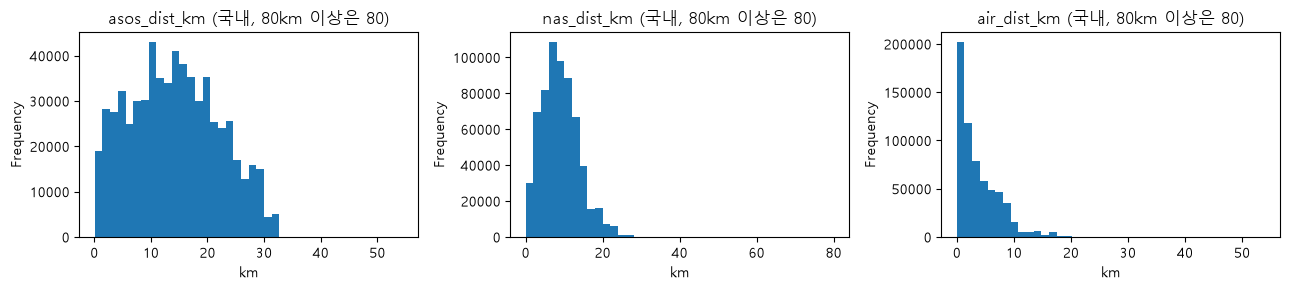

In [31]:
def nearest(pts, st, sid):
    P = np.radians(pts[['lat', 'lon']].to_numpy(float)); S = np.radians(st[['lat', 'lon']].to_numpy(float))
    out_id, out_d = np.empty(len(P), dtype=object), np.empty(len(P))
    for i in range(0, len(P), 2000):                      # 메모리 절약: 2천 좌표씩
        p = P[i:i + 2000]
        a = np.sin((p[:, None, 0] - S[None, :, 0]) / 2) ** 2 + np.cos(p[:, None, 0]) * np.cos(S[None, :, 0]) * np.sin((p[:, None, 1] - S[None, :, 1]) / 2) ** 2
        d = 2 * 6371.0 * np.arcsin(np.sqrt(np.clip(a, 0, 1)))
        j = d.argmin(axis=1)
        out_id[i:i + 2000] = st[sid].to_numpy()[j]; out_d[i:i + 2000] = d[np.arange(len(p)), j]
    return out_id, out_d.round(2)

dom = J['src_route'] == 'domestic'
pts = J.loc[dom & J['lat_use'].notna(), ['lat_use', 'lon_use']].drop_duplicates().rename(columns={'lat_use': 'lat', 'lon_use': 'lon'}).reset_index(drop=True)
for pre, st, sid in [('asos', asos_stn, 'stn_id'), ('nas', nas_stn, 'obsr_spot_code'), ('air', air_stn, 'station_nm')]:
    pts[f'{pre}_stn'], pts[f'{pre}_dist_km'] = nearest(pts, st, sid)
pts.to_parquet(OUT / '34_station_map.parquet', index=False)
J = J.merge(pts, left_on=['lat_use', 'lon_use'], right_on=['lat', 'lon'], how='left', suffixes=('', '_m')).drop(columns=['lat_m', 'lon_m'])
assert len(J) == len(base)
print(f"국내 고유 좌표 {len(pts):,}개 (국내 {dom.sum():,}행 중 좌표 보유 {(dom & J['lat_use'].notna()).sum():,}행)")
display(J.loc[dom, ['asos_dist_km', 'nas_dist_km', 'air_dist_km']].describe(percentiles=[.5, .9, .99]).T[['count', 'mean', '50%', '90%', '99%', 'max']])
fig, axes = plt.subplots(1, 3, figsize=(13, 3))
for ax, c in zip(axes, ['asos_dist_km', 'nas_dist_km', 'air_dist_km']):
    J.loc[dom, c].clip(upper=80).plot(kind='hist', bins=40, ax=ax, title=c + ' (국내, 80km 이상은 80)'); ax.set_xlabel('km')
plt.tight_layout(); plt.show()

### 6-3. 기준일 창 집계 — ASOS / NAS
지점×날짜 격자(빈 날짜 포함)에서 trailing rolling 을 계산하고, 각 행의 (지점, 기준일) 칸 값을 바로 꺼낸다(대용량 병합 없음).
* `_d0` = 기준일 당일, `_mean7d / _sum7d / _max7d / _min7d` = D-6~D0, `_mean30d / _sum30d` = D-29~D0.
* 최소 관측일: 7일 창 4일, 30일 창 15일. 창 안 관측일 수 `*_nobs7d`, `*_nobs30d` 로 품질 확인.

In [32]:
def attach_windows(J, daily, id_col, date_col, key_col, spec, prefix, obs_col, mask=None):
    """spec = {컬럼: ['d0', ('mean',7), ('sum',30), ...]} → J 에 float32 컬럼 추가"""
    t0 = time.time()
    d = daily[[id_col, date_col] + sorted(set(spec) | {obs_col})].copy()
    d[date_col] = pd.to_datetime(d[date_col]).astype('datetime64[ns]')
    ids = pd.Index(sorted(set(J[key_col].dropna()) & set(d[id_col])))
    d = d[d[id_col].isin(ids)].drop_duplicates([id_col, date_col])
    dates = pd.date_range(d[date_col].min(), d[date_col].max(), freq='D')
    di = dates.get_indexer(pd.DatetimeIndex(J['base_date'].astype('datetime64[ns]'))); si = ids.get_indexer(J[key_col])
    ok = (di >= 0) & (si >= 0) & (np.ones(len(J), bool) if mask is None else mask.to_numpy())
    new = {}
    def put(name, arr):
        v = np.full(len(J), np.nan, dtype='float32'); v[ok] = arr[di[ok], si[ok]]; new[name] = v
    wide_cache = {}
    def wide(c):
        if c not in wide_cache:
            wide_cache[c] = d.pivot(index=date_col, columns=id_col, values=c).reindex(index=dates, columns=ids).astype('float32')
        return wide_cache[c]
    for c, aggs in spec.items():
        for a in aggs:
            if a == 'd0':
                put(f'{prefix}{c}_d0', wide(c).to_numpy())
            else:
                fn, w = a
                put(f'{prefix}{c}_{fn}{w}d', getattr(wide(c).rolling(w, min_periods=4 if w == 7 else 15), fn)().to_numpy())
    obs = wide(obs_col).notna().astype('float32')
    for w in (7, 30):
        put(f'{prefix}nobs{w}d', obs.rolling(w, min_periods=1).sum().to_numpy())
    print(f'{prefix}: {len(new)}개 컬럼, 지점 {len(ids)}개 × {len(dates):,}일, 값 붙은 행 {ok.sum():,} ({time.time() - t0:.0f}초)')
    return pd.concat([J, pd.DataFrame(new, index=J.index)], axis=1)

W3 = ['d0', ('mean', 7), ('mean', 30)]
asos['rain_day'] = (asos['sum_rn'].fillna(0) >= 1.0).astype(float).where(asos['avg_ta'].notna())
J = attach_windows(J, asos, 'stn_id', 'meas_date', 'asos_stn', {
    'avg_ta': W3, 'max_ta': ['d0', ('max', 7), ('max', 30)], 'min_ta': ['d0', ('min', 7), ('min', 30)],
    'sum_rn': ['d0', ('sum', 7), ('sum', 30)], 'rain_day': [('sum', 7), ('sum', 30)], 'avg_ws': W3,
    'sum_sshr_num': ['d0', ('sum', 7), ('mean', 30)], 'sum_gsr': ['d0', ('sum', 7), ('mean', 30)],
    'avg_ts': W3, 'avg_cm5_te': W3, 'avg_cm10_te': W3, 'avg_cm20_tes': W3}, 'asos_', 'avg_ta', mask=dom)
J = attach_windows(J, nas, 'obsr_spot_code', 'meas_date', 'nas_stn', {
    'temp': W3, 'hghst_artmp': ['d0', ('max', 7)], 'lowst_artmp': ['d0', ('min', 7)], 'rn': ['d0', ('sum', 7), ('sum', 30)], 'wind': W3,
    'sun_time_num': ['d0', ('sum', 7), ('mean', 30)], 'srqty': ['d0', ('sum', 7), ('mean', 30)],
    'gr_temp': W3, 'soil_temp': W3, 'soil_wt': W3}, 'nas_', 'temp', mask=dom)
assert len(J) == len(base)
display(nn_table(J, ['asos_avg_ta_d0', 'asos_avg_ta_mean7d', 'asos_avg_ta_mean30d', 'asos_sum_rn_sum7d', 'asos_sum_sshr_num_sum7d', 'asos_sum_gsr_sum7d', 'asos_avg_cm10_te_mean7d',
                     'nas_temp_mean7d', 'nas_rn_sum7d', 'nas_sun_time_num_sum7d', 'nas_srqty_sum7d', 'nas_soil_temp_mean7d', 'nas_soil_wt_mean7d']))

asos_: 37개 컬럼, 지점 98개 × 4,133일, 값 붙은 행 628,895 (2초)


nas_: 30개 컬럼, 지점 212개 × 4,133일, 값 붙은 행 628,895 (3초)


,컬럼,비결측%_domestic,비결측%_overseas,전체%
0,asos_avg_ta_d0,97.1,0.0,90.3
1,asos_avg_ta_mean7d,97.2,0.0,90.4
2,asos_avg_ta_mean30d,97.2,0.0,90.4
3,asos_sum_rn_sum7d,97.2,0.0,90.4
4,asos_sum_sshr_num_sum7d,97.1,0.0,90.3
5,asos_sum_gsr_sum7d,61.6,0.0,57.3
6,asos_avg_cm10_te_mean7d,33.3,0.0,31.0
7,nas_temp_mean7d,90.2,0.0,83.8
8,nas_rn_sum7d,96.2,0.0,89.5
9,nas_sun_time_num_sum7d,39.1,0.0,36.4


In [33]:
# 연도별 커버리지: 기상 창 값이 붙은 국내 행 비율
cov_y = J[dom].groupby('base_year')[['asos_avg_ta_mean7d', 'nas_temp_mean7d', 'nas_soil_wt_mean7d']].apply(lambda d: d.notna().mean() * 100).round(1)
display(cov_y.T)

base_year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
asos_avg_ta_mean7d,87.5,87.0,95.1,95.8,96.3,97.1,96.4,96.9,98.5,98.6,98.5,98.2
nas_temp_mean7d,75.0,85.3,83.1,85.2,87.8,90.9,92.0,92.3,90.7,91.0,91.8,93.4
nas_soil_wt_mean7d,20.8,30.8,25.3,24.3,55.1,61.0,60.6,59.0,57.8,56.6,57.5,56.3


### 6-4. 토양 pH — 법정동×연도 → 법정동(전 연도) → 시군구×연도 → 시군구(전 연도)
매칭 단계는 `soil_match_level` 에 남긴다. 조사 연도가 기준일 연도와 다르면 값이 시점을 대표하지 못할 수 있다.

In [34]:
SC = ['soil_ph_mean', 'vldpha_mean', 'om_mean']
def wmean(df, keys):
    g = df.assign(**{c: df[c] * df['n_samples'] for c in SC}).groupby(keys)[SC + ['n_samples']].sum()
    for c in SC: g[c] = g[c] / g['n_samples']
    return g
L = [('L1 법정동×연도', wmean(soil_dong, ['legal_dong_code', 'yr'])[SC], ['legal_dong_code', 'base_year']),
     ('L2 법정동 전연도', wmean(soil_dong, ['legal_dong_code'])[SC], ['legal_dong_code']),
     ('L3 시군구×연도', wmean(soil_sgg, ['sgg_cd', 'yr'])[SC], ['sgg_cd', 'base_year']),
     ('L4 시군구 전연도', wmean(soil_sgg, ['sgg_cd'])[SC], ['sgg_cd'])]
vals = pd.DataFrame(np.nan, index=J.index, columns=SC); lvl = pd.Series(None, index=J.index, dtype=object)
for name, tbl, keys in L:
    todo = dom & vals['soil_ph_mean'].isna()
    k = pd.MultiIndex.from_frame(J.loc[todo, keys]) if len(keys) > 1 else pd.Index(J.loc[todo, keys[0]])
    pos = tbl.index.get_indexer(k); hit = pos >= 0
    idx = J.index[todo][hit]
    vals.loc[idx, SC] = tbl.to_numpy()[pos[hit]]; lvl.loc[idx] = name
    print(f'{name}: +{hit.sum():,}행')
J['soil_ph'], J['soil_vldpha'], J['soil_om'], J['soil_match_level'] = vals['soil_ph_mean'], vals['vldpha_mean'], vals['om_mean'], lvl
display(J.loc[dom, 'soil_match_level'].value_counts(dropna=False).rename('국내 행').to_frame().T)
display(J.loc[dom, ['soil_ph', 'soil_vldpha', 'soil_om']].describe().T[['count', 'mean', '50%', 'min', 'max']])

L1 법정동×연도: +90,859행
L2 법정동 전연도: +79,884행
L3 시군구×연도: +443,537행
L4 시군구 전연도: +5,892행


soil_match_level,L3 시군구×연도,L1 법정동×연도,L2 법정동 전연도,NaN,L4 시군구 전연도
국내 행,443537,90859,79884,8723,5892


,count,mean,50%,min,max
soil_ph,620172.0,6.434958,6.385714,3.5,9.5
soil_vldpha,620172.0,422.761884,381.101460,0.0,4107.5
soil_om,620172.0,25.916047,24.188951,0.0,300.0


### 6-5. 대기 — 최근접 측정소 + 창

In [35]:
J = attach_windows(J, air, 'station_nm', 'msur_dt', 'air_stn', {'no2_value': W3, 'co_value': W3, 'so2_value': W3}, 'air_', 'no2_value', mask=dom)
assert len(J) == len(base)
display(nn_table(J, ['air_no2_value_d0', 'air_no2_value_mean7d', 'air_co_value_mean7d', 'air_so2_value_mean7d', 'air_no2_value_mean30d']))

air_: 11개 컬럼, 지점 630개 × 4,133일, 값 붙은 행 627,979 (4초)


,컬럼,비결측%_domestic,비결측%_overseas,전체%
0,air_no2_value_d0,85.0,0.0,79.0
1,air_no2_value_mean7d,85.1,0.0,79.1
2,air_co_value_mean7d,85.0,0.0,79.0
3,air_so2_value_mean7d,85.1,0.0,79.1
4,air_no2_value_mean30d,85.2,0.0,79.2


### 6-6. 해외 (수입 건) — alpha-2 → alpha-3 → 국가×기준일 창, 국가별 토양 pH

In [36]:
J['nation_a3'] = J['nation_a2'].map(A2A3).where(ovs)
J = attach_windows(J, gw, 'alpha_3', 'date', 'nation_a3', {
    'temperature_mean': W3, 'temperature_max': [('max', 7)], 'temperature_min': [('min', 7)], 'precipitation_sum': ['d0', ('sum', 7), ('sum', 30)],
    'relative_humidity_mean': W3, 'soil_moisture_mean': W3, 'sunshine_duration': ['d0', ('sum', 7)], 'wind_speed_mean': W3, 'shortwave_radiation_sum': ['d0', ('sum', 7)]},
    'gw_', 'temperature_mean', mask=ovs)
gs = soil_global.drop_duplicates('iso3').set_index('iso3')
J['gsoil_ph'] = J['nation_a3'].map(gs['ph_mean']); J['gsoil_ph_std'] = J['nation_a3'].map(gs['ph_std'])
assert len(J) == len(base)
print(f"수입 {ovs.sum():,}행: alpha-3 변환 {J.loc[ovs, 'nation_a3'].notna().mean():.1%}")
display(nn_table(J[ovs], ['nation_a3', 'gw_temperature_mean_d0', 'gw_temperature_mean_mean7d', 'gw_precipitation_sum_sum7d', 'gw_soil_moisture_mean_mean7d', 'gw_sunshine_duration_sum7d', 'gsoil_ph']))
display(J.loc[ovs, 'nation_a3'].value_counts().head(10).rename('수입 행').to_frame().T)

gw_: 23개 컬럼, 지점 95개 × 4,079일, 값 붙은 행 45,536 (2초)
수입 47,642행: alpha-3 변환 95.6%


,컬럼,비결측%_overseas,전체%
0,nation_a3,95.6,95.6
1,gw_temperature_mean_d0,95.6,95.6
2,gw_temperature_mean_mean7d,95.6,95.6
3,gw_precipitation_sum_sum7d,95.6,95.6
4,gw_soil_moisture_mean_mean7d,95.6,95.6
5,gw_sunshine_duration_sum7d,95.6,95.6
6,gsoil_ph,95.6,95.6


nation_a3,USA,ITA,FRA,CHN,ESP,NLD,DEU,AUS,THA,NZL
수입 행,8373,7385,6567,2282,2094,1810,1482,1396,1314,1314


## 7. (참고) 수분활성도 · 식품 pH · 염도 — PPT 1·3·4순위

매핑 시트2·3 은 이 세 인자를 "DB 없음(t_aw_cl 은 사용자 결정으로 제외) / 수집 경로 -" 로 적었다. 확인할 것 두 가지:
1. 리서치팀 폴더의 `통합_수분활성도_수분함량_식품pH_염도_최종.xlsx`(가이드.txt: "식품마다의 수분함량, ph, 염도") 와 DB `ba_data.t_aw_cl` 이 **같은 자료인지**.
2. 같다면 품목코드로 우리 데이터에 얼마나 붙는지 (`file_*` 컬럼, **모델 투입 여부는 결정 필요** — 테이블목록의 '곰팡이 독소 전용' 표기는 `aflatoxin_aw` 등급 컬럼에 대한 것으로 보임).

In [37]:
def parse_val(s):
    """'0.91~0.98'→(0.91,0.98,0.945) / '<0.6'→(nan,0.6,0.6) / '>0.98'→(0.98,nan,0.98) / '0.55'→(0.55,0.55,0.55) / '-'→nan"""
    if s is None or (isinstance(s, float) and np.isnan(s)): return (np.nan, np.nan, np.nan)
    t = str(s).strip()
    if t in ('', '-'): return (np.nan, np.nan, np.nan)
    t = t.replace(' ', '').replace('∼', '~').replace('–', '~').replace('-', '~').replace('..', '.')   # '6..00' 같은 오타 보정
    m = re.match(r'^([<≤>≥]?)(\d+(?:\.\d+)?)(?:~(\d+(?:\.\d+)?))?$', t)
    if not m: return (np.nan, np.nan, np.nan)
    sign, a, b = m.group(1), float(m.group(2)), (float(m.group(3)) if m.group(3) else None)
    if b is not None: return (min(a, b), max(a, b), (a + b) / 2)
    if sign in ('<', '≤'): return (np.nan, a, a)
    if sign in ('>', '≥'): return (a, np.nan, a)
    return (a, a, a)

aw_file = pd.read_excel(RESEARCH / '통합_수분활성도_수분함량_식품pH_염도_최종.xlsx', sheet_name='값')
aw_db = collect('80_t_aw_cl', "SELECT * FROM ba_data.t_aw_cl", source='ba_data.t_aw_cl (참고)')
print(f"파일 {len(aw_file)}행 (코드 {aw_file['PRDLST_CD'].nunique()}) | DB t_aw_cl {len(aw_db)}행 (코드 {aw_db['prdlst_cd'].nunique()}) | 컬럼 {list(aw_db.columns)}")
both = aw_file.merge(aw_db.drop_duplicates('prdlst_cd'), left_on='PRDLST_CD', right_on='prdlst_cd', how='left')
rows = [{'항목': '파일 품목코드가 DB 에 있음', '일치%': round(both['prdlst_cd'].notna().mean() * 100, 1), '불일치 품목': int(both['prdlst_cd'].isna().sum())}]
for f, d in [('식품 pH', 'ph'), ('염도', 'na'), ('수분함량', 'mc'), ('수분활성도', 'aw')]:
    a = np.array([parse_val(v)[2] for v in both[f]]); b = np.array([parse_val(v)[2] for v in both[d]])
    eq = (np.isnan(a) & np.isnan(b)) | (np.abs(a - b) < 1e-9)
    rows.append({'항목': f'{f} 값 일치 (숫자 기준)', '일치%': round(eq.mean() * 100, 1), '불일치 품목': int((~eq).sum()),
                 '불일치 중 파일 빈칸→DB 값': int((np.isnan(a) & ~np.isnan(b)).sum())})
display(pd.DataFrame(rows))
print('DB aw_source 분포:', aw_db['aw_source'].str.split('(').str[0].value_counts().to_dict())
print(f"DB 에만 있는 코드 {(~aw_db['prdlst_cd'].isin(aw_file['PRDLST_CD'])).sum()}개 = 상위 분류(곡류·과일류 등) 대표값")
print('→ t_aw_cl 은 이 파일을 적재한 것이고, 파일에 없는 수분활성도는 상위 분류 중앙값으로 채우고 상위 분류 코드를 추가한 버전이다.')

[80_t_aw_cl] 캐시: 1,316행 × 9열 (0초) ← ba_data.t_aw_cl (참고)
파일 653행 (코드 653) | DB t_aw_cl 1316행 (코드 1316) | 컬럼 ['prdlst_cd', 'kor_nm', 'lv', 'aw', 'mc', 'ph', 'na', 'aflatoxin_aw', 'aw_source']


,항목,일치%,불일치 품목,불일치 중 파일 빈칸→DB 값
0,파일 품목코드가 DB 에 있음,100.0,0,NaN
1,식품 pH 값 일치 (숫자 기준),100.0,0,0.0
2,염도 값 일치 (숫자 기준),100.0,0,0.0
3,수분함량 값 일치 (숫자 기준),99.1,6,1.0
4,수분활성도 값 일치 (숫자 기준),78.1,143,135.0


DB aw_source 분포: {'original': 1251, 'assigned_1': 16, 'recomputed': 11, 'derived_median': 9, 'mapped_from:C0309 ': 2, 'mapped_from:C0310': 2, 'mapped_from:C0312': 2, 'mapped_from:C0313': 2, 'mapped_from:C0323 ': 2, 'mapped_from:C0313 절임류·조림류': 1, 'mapped_from:C0316 식육가공품·포장육': 1, 'assigned_0 건조 제품 ': 1, 'mapped_from:C0303': 1, 'mapped_from:C0305': 1, 'assigned_0 결정 당': 1, 'mapped_from:C0306': 1, 'assigned_0 유지': 1, 'mapped_from:C0309': 1, 'mapped_from:C0314': 1, 'assigned_0 건조 수산물': 1, 'mapped_from:C0318': 1, 'mapped_from:C0317': 1, 'assigned_2 빵류 0.84~0.96 · 떡류 >0.96 ': 1, 'mapped_from:C0304 ': 1, 'assigned_2 어묵 ~0.95 ': 1, 'mapped_from:C0308 ': 1, 'mapped_from:C0311 ': 1, 'mapped_from:C0319 ': 1}
DB 에만 있는 코드 663개 = 상위 분류(곡류·과일류 등) 대표값
→ t_aw_cl 은 이 파일을 적재한 것이고, 파일에 없는 수분활성도는 상위 분류 중앙값으로 채우고 상위 분류 코드를 추가한 버전이다.


In [38]:
# parse_val 은 위 셀에서 정의

aw = aw_file[['PRDLST_CD', 'KOR_NM', 'LV']].copy()
for s, dname in [('수분활성도', 'aw'), ('수분함량', 'moist'), ('식품 pH', 'food_ph'), ('염도', 'salt')]:
    p = [parse_val(v) for v in aw_file[s]]
    aw[f'{dname}_min'], aw[f'{dname}_max'], aw[dname] = [x[0] for x in p], [x[1] for x in p], [x[2] for x in p]
AWC = [c for c in aw.columns if c not in ('PRDLST_CD', 'KOR_NM', 'LV')]
print('파싱 후 값 있는 품목 수:', {c: int(aw[c].notna().sum()) for c in ['aw', 'moist', 'food_ph', 'salt']})
awt = aw.set_index('PRDLST_CD')

# 우리 품목코드 → 없으면 식품공전 분류의 상위 품목코드(hrnk_prdlst_cd)로 한 단계씩 올라가며 찾기 (최대 4단계)
parent = cl1.set_index('prdlst_cd')['hrnk_prdlst_cd']
cur = J['prdlst_code_use'].copy(); lvl = pd.Series(None, index=J.index, dtype=object); found = pd.Series(None, index=J.index, dtype=object)
for step in range(5):
    hit = found.isna() & cur.isin(awt.index)
    found[hit] = cur[hit]; lvl[hit] = '정확' if step == 0 else f'상위 {step}단계'
    cur = cur.map(parent).where(found.isna())
fv = awt.reindex(found.fillna('__none__'))
for c in AWC: J[f'file_{c}'] = fv[c].to_numpy()
J['file_match_level'] = lvl; J['file_match_nm'] = fv['KOR_NM'].to_numpy()
display(J['file_match_level'].value_counts(dropna=False).rename('행').to_frame().T)
display(nn_table(J, ['file_aw', 'file_moist', 'file_food_ph', 'file_salt']))
print('참고: DB 몸통 aw_grade(아플라톡신용 등급) 분포:', J['aw_grade'].value_counts(dropna=False).to_dict())

파싱 후 값 있는 품목 수: {'aw': 456, 'moist': 544, 'food_ph': 382, 'salt': 500}


file_match_level,NaN,정확,상위 1단계,상위 2단계
행,395064,269047,10780,1646


,컬럼,비결측%_domestic,비결측%_overseas,전체%
0,file_aw,30.2,47.9,31.4
1,file_moist,32.6,51.3,33.9
2,file_food_ph,33.4,48.7,34.5
3,file_salt,35.0,53.5,36.3


참고: DB 몸통 aw_grade(아플라톡신용 등급) 분포: {1: 381619, 2: 273015, 0: 21903}


## 8. 결과
### 8-1. 최종 테이블 저장 + 컬럼 그룹별 커버리지

저장: C:\Users\NT751\Desktop\천영진\리스테리아ML\data\collected\listeria_joined.parquet — 676,537행 × 233열 (140 MB)


,그룹,전체%,국내%,수입%,검출%,불검출%
0,식품 유형: 품목분류(원본+식품공전),100.0,100.0,100.0,100.0,100.0
1,식품 유형: 제조조건(대장),0.2,0.2,0.0,0.0,0.2
2,저장·유통 온도 대체: 운반온도·시료상태,8.7,3.0,84.4,7.7,8.7
3,저장·유통 온도 대체: 유통기한·보존기준(대장),28.8,31.0,0.0,11.4,28.8
4,포장 유형 대체: 포장재질(대장),27.2,29.3,0.0,10.3,27.3
5,수입 물류(선적·입항),7.0,0.0,99.6,6.3,7.0
6,기온 (ASOS/NAS/해외),99.7,100.0,95.6,99.4,99.7
7,강수 (ASOS/NAS/해외),99.7,100.0,95.6,99.4,99.7
8,바람 (ASOS/NAS/해외),99.6,99.9,95.6,99.4,99.6
9,일조·일사 (ASOS/NAS/해외),99.6,99.9,95.6,99.4,99.6


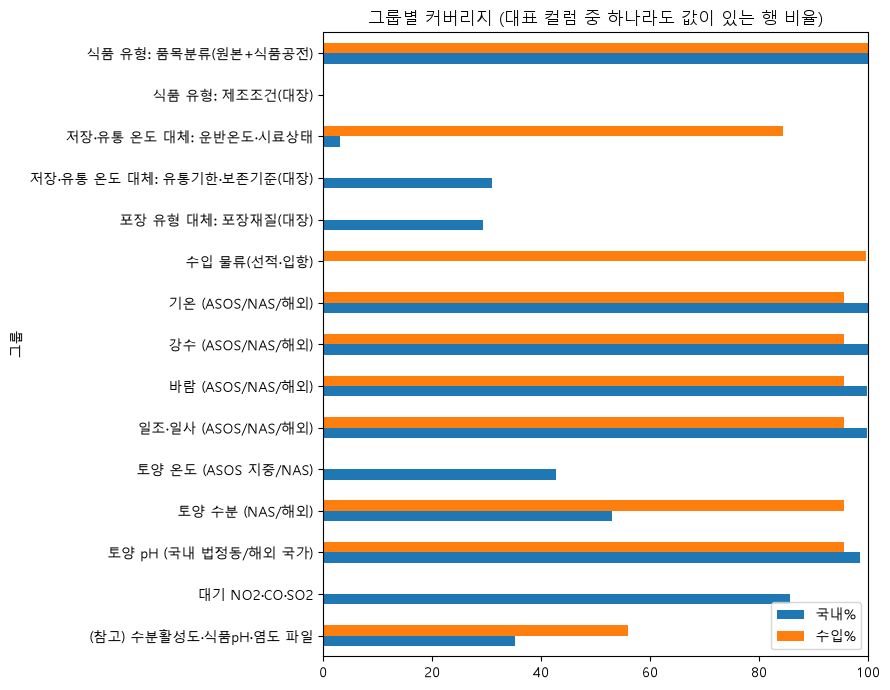

In [39]:
FINAL = OUT / 'listeria_joined.parquet'
drop = [c for c in ['lat_db', 'lon_db', 'hazard_label', 'data_source', 'result_value_num', 'judge_stdr', 'judge_stdr_num'] if c in J.columns]
final = J.drop(columns=drop)
for c in final.columns:
    if final[c].dtype == object:
        final[c] = final[c].astype('string')
final.to_parquet(FINAL, index=False)
print(f'저장: {FINAL} — {len(final):,}행 × {final.shape[1]}열 ({FINAL.stat().st_size / 1e6:.0f} MB)')

GROUPS = {
    '식품 유형: 품목분류(원본+식품공전)': ['train_prdlst_nm', 'cl_lv', 'food_hf_ls_cl_cd'],
    '식품 유형: 제조조건(대장)': ['mnf_cnd_cn'],
    '저장·유통 온도 대체: 운반온도·시료상태': ['cnvync_sttus_tp', 'splore_sttus_nm'],
    '저장·유통 온도 대체: 유통기한·보존기준(대장)': ['pog_daycnt', 'prsrv_distb_stdr_cn'],
    '포장 유형 대체: 포장재질(대장)': ['frmlc_mtrqlt'],
    '수입 물류(선적·입항)': ['shipng_de', 'entrpt_de'],
    '기온 (ASOS/NAS/해외)': ['asos_avg_ta_mean7d', 'nas_temp_mean7d', 'gw_temperature_mean_mean7d'],
    '강수 (ASOS/NAS/해외)': ['asos_sum_rn_sum7d', 'nas_rn_sum7d', 'gw_precipitation_sum_sum7d'],
    '바람 (ASOS/NAS/해외)': ['asos_avg_ws_mean7d', 'nas_wind_mean7d', 'gw_wind_speed_mean_mean7d'],
    '일조·일사 (ASOS/NAS/해외)': ['asos_sum_sshr_num_sum7d', 'asos_sum_gsr_sum7d', 'nas_sun_time_num_sum7d', 'nas_srqty_sum7d', 'gw_sunshine_duration_sum7d'],
    '토양 온도 (ASOS 지중/NAS)': ['asos_avg_cm10_te_mean7d', 'nas_soil_temp_mean7d'],
    '토양 수분 (NAS/해외)': ['nas_soil_wt_mean7d', 'gw_soil_moisture_mean_mean7d'],
    '토양 pH (국내 법정동/해외 국가)': ['soil_ph', 'gsoil_ph'],
    '대기 NO2·CO·SO2': ['air_no2_value_mean7d', 'air_co_value_mean7d', 'air_so2_value_mean7d'],
    '(참고) 수분활성도·식품pH·염도 파일': ['file_aw', 'file_food_ph', 'file_salt'],
}
rows = []
for g, cols in GROUPS.items():
    anyv = final[cols].notna().any(axis=1)
    rows.append({'그룹': g, '전체%': round(anyv.mean() * 100, 1), '국내%': round(anyv[final.src_route == 'domestic'].mean() * 100, 1),
                 '수입%': round(anyv[final.src_route == 'overseas'].mean() * 100, 1),
                 '검출%': round(anyv[final.judge_result == '검출'].mean() * 100, 1), '불검출%': round(anyv[final.judge_result == '불검출'].mean() * 100, 1)})
cov = pd.DataFrame(rows); display(cov)
cov.to_csv(OUT / 'coverage_summary.csv', index=False, encoding='utf-8-sig')
ax = cov.set_index('그룹')[['국내%', '수입%']].iloc[::-1].plot(kind='barh', figsize=(9, 7), title='그룹별 커버리지 (대표 컬럼 중 하나라도 값이 있는 행 비율)'); ax.set_xlim(0, 100); plt.tight_layout(); plt.show()

### 8-2. 누수 점검 — 검출/불검출에 따라 결측률이 크게 다른 컬럼
결측 여부 자체가 판정과 얽혀 있으면(예: 특정 검사 경로에서만 값이 채워짐) 모델이 결측 패턴으로 정답을 배울 수 있다. 차이 10%p 이상을 표시한다.

In [40]:
cands = [c for c in final.columns if c.startswith(('asos_', 'nas_', 'air_', 'gw_', 'soil_', 'file_', 'flag_', 'days_')) or c in sum(GROUPS_ATTR.values(), [])]
cands = [c for c in dict.fromkeys(cands) if c in final.columns and not c.endswith(('_stn', '_dist_km'))]
g = final.groupby('judge_result', observed=True)[cands].apply(lambda d: d.notna().mean() * 100).T.round(1)
g['차이(검출-불검출)%p'] = (g['검출'] - g['불검출']).round(1)
flag = g[g['차이(검출-불검출)%p'].abs() >= 10].sort_values('차이(검출-불검출)%p')
print(f'점검 {len(cands)}개 컬럼 중 결측률 차이 10%p 이상: {len(flag)}개'); display(flag)

점검 170개 컬럼 중 결측률 차이 10%p 이상: 26개


judge_result,검출,불검출,차이(검출-불검출)%p
file_salt,16.1,36.4,-20.3
file_salt_min,16.1,36.4,-20.3
file_salt_max,16.1,36.4,-20.3
file_food_ph_max,15.7,34.5,-18.8
file_food_ph,15.7,34.5,-18.8
file_food_ph_min,15.7,34.5,-18.8
file_match_level,23.5,41.7,-18.2
file_match_nm,23.5,41.7,-18.2
file_moist_min,16.1,34.0,-17.9
file_moist,16.1,34.0,-17.9


### 8-3. 매핑 엑셀(시트1·2) 컬럼별 실제 수집 여부
매핑에 적힌 (테이블, 컬럼) 이 이 노트북에서 받았는지 자동으로 대조한다. 안 받은 컬럼은 사유를 붙인다.

In [41]:
GOT = {
    'kma_asos_daily_info': set(asos.columns) | {'sum_sshr'}, 'nas_agri_weather_daily_info': set(nas.columns) | {'sun_time'},
    'kma_ground_obs_station_info': set(asos_stn.columns), 'nas_agri_weather_obs_station': {'obsr_spot_code', 'clmt_zone_code', 'legaldong_code', 'instl_la', 'instl_lo'},
    'soil_ph_info': {'acid', 'vldpha', 'om', 'legal_dong_code', 'any_year'}, 'global_soil_ph': set(soil_global.columns),
    'keco_airkorea_fine_dust_info': set(air.columns), 'keco_airkorea_obs_station': {'station_nm', 'dm_x', 'dm_y', 'legaldong_code'},
    'global_weather_info': set(gw.columns), 'm_org_lims_data_info': set(m_org.columns), 't_prdlst_mnf_ledg': set(ledg.columns),
    't_bsn_lcns_ledg': set(bsn.columns), 't_prdlst_cl': set(cl.columns) | {'lv', 'dfn'}, 's_org_lims_data_info': set(s_org_raw.columns),
    's_co_ifd_ovsmnfst_regstr_m': set(co.columns), 'hazard_preprocessed_data': set(body_db.columns) | set(pq.columns),
}
WHY = {'kma_weather_predict_info': '예보 테이블(1,068행, 테이블목록 "미사용") — 과거 관측과 조인 불가',
       'max_ta_hrmt': '발생 시각(text) — 일 단위 모델에 불필요', 'min_ta_hrmt': '발생 시각(text)', 'sum_rn_dur': '강수 계속시간(text)', 'ss_dur': '일조 가능시간(천문값)',
       'n99_rn': 'sum_rn 과 중복(9시 기준)', 'hr_1_max_rn': '보조', 'mi_10_max_rn': '보조', 'max_ws_wd': '풍향(각도) — 보조', 'max_ins_ws_wd': '풍향(각도) — 보조', 'max_ws1': '최다풍향 — 보조',
       'hr_24_sum_rws': '보조', 'hr_1_max_icsr': '보조', 'avg_m05_te': '깊은 지중온도(0.5m 이상) — 보조', 'avg_m10_te': '보조', 'avg_m15_te': '보조', 'avg_m30_te': '보조', 'avg_m50_te': '보조',
       'widdir': '풍향 — 정의서 "하류 미사용"', 'exam_day': '정의서 "연 단위 집계 시 사용하지 않음"', 'pnu_cd': '필지 키 — 법정동으로 집계', 'wind_speed_max': '보조',
       'prdlst_report_no': '조인 키로만 사용', 'packng_plc_addr': '주소 텍스트 — 보조', 'station_nm': '조인 키', 'msur_dt': '조인 키'}
mm = pd.concat([m1[['변수 그룹', '테이블', '컬럼']].rename(columns={'변수 그룹': '인자'}).assign(시트='1'),
                m2[['변수', '테이블', '컬럼']].rename(columns={'변수': '인자'}).assign(시트='2')])
mm['수집'] = [c in GOT.get(t, set()) for t, c in zip(mm['테이블'], mm['컬럼'])]
mm['안 받은 사유'] = [('' if ok else WHY.get(c, WHY.get(t, '확인 필요'))) for ok, t, c in zip(mm['수집'], mm['테이블'], mm['컬럼'])]
u = mm.drop_duplicates(['테이블', '컬럼'])
print(f"매핑 고유 (테이블, 컬럼) {len(u)}개 중 수집 {u['수집'].sum()}개 / 미수집 {(~u['수집']).sum()}개")
display(u[~u['수집']][['시트', '인자', '테이블', '컬럼', '안 받은 사유']].reset_index(drop=True))

매핑 고유 (테이블, 컬럼) 117개 중 수집 87개 / 미수집 30개


,시트,인자,테이블,컬럼,안 받은 사유
0,1,기온,kma_asos_daily_info,max_ta_hrmt,발생 시각(text) — 일 단위 모델에 불필요
1,1,기온,kma_asos_daily_info,min_ta_hrmt,발생 시각(text)
2,1,기온,kma_weather_predict_info,temp,"예보 테이블(1,068행, 테이블목록 ""미사용"") — 과거 관측과 조인 불가"
3,1,기온,kma_weather_predict_info,hghst_artmp,"예보 테이블(1,068행, 테이블목록 ""미사용"") — 과거 관측과 조인 불가"
4,1,기온,kma_weather_predict_info,lowst_artmp,"예보 테이블(1,068행, 테이블목록 ""미사용"") — 과거 관측과 조인 불가"
5,1,강수,kma_asos_daily_info,n99_rn,sum_rn 과 중복(9시 기준)
6,1,강수,kma_asos_daily_info,sum_rn_dur,강수 계속시간(text)
7,1,강수,kma_asos_daily_info,hr_1_max_rn,보조
8,1,강수,kma_asos_daily_info,mi_10_max_rn,보조
9,1,강수,kma_weather_predict_info,precip_mm,"예보 테이블(1,068행, 테이블목록 ""미사용"") — 과거 관측과 조인 불가"


### 8-4. 인자별 최종 상태 (PPT 기준)

| PPT 순위 | 인자 | 상태 | 주요 컬럼 (`listeria_joined.parquet`) | 비고 |
|---|---|---|---|---|
| 1 | 수분활성도 | **DB 매핑에서 제외됨 → 7장 참고 조인** | `file_aw(_min/_max)` | 리서치팀 파일이 DB `t_aw_cl` 의 원천(pH·염도 100% 일치). 사용 여부 결정 필요 |
| 1 | 온도(기온) | 수집 | `asos_avg_ta_*`, `asos_max_ta_*`, `nas_temp_*` / 수입 `gw_temperature_*` | 최근접 관측소, D0·7일·30일 |
| 3 | 식품 pH | 7장 참고 조인 | `file_food_ph` | 위와 동일 |
| 4 | 염도 | 7장 참고 조인 | `file_salt` | 위와 동일 |
| 5 | 토양 온도 | 수집 | `asos_avg_cm5/10/20_*`, `asos_avg_ts_*`, `nas_soil_temp_*`, `nas_gr_temp_*` | 출처 문서(농진청 상세관측)와 달리 깊이별 값은 ASOS 에만 있음 |
| 6 | 토양 수분 | 수집(단일 깊이) | `nas_soil_wt_*` / 수입 `gw_soil_moisture_*` | 깊이별·유역별·흙토람 자료는 DB 없음 → 시트3 |
| 7 | 대기조성 | **대체 수집** | `air_no2/co/so2_*` | CO2 는 DB 없음 → 시트3 (`co_value` 는 CO) |
| 8 | 토양 pH | 수집 | `soil_ph`, `soil_vldpha`, `soil_om` (`soil_match_level`) / 수입 `gsoil_ph` | 조사 연도 ≠ 기준일 연도일 수 있음 |
| 9 | 강수 | 수집 | `asos_sum_rn_*`, `asos_rain_day_*`, `nas_rn_*` / 수입 `gw_precipitation_*` | |
| 추가 | 식품 유형 | 수집 | `train_prdlst_*`, `statistic_prdlst_nm_*`, `cl_*`, `food_hf_ls_cl_cd`, `mnf_cnd_cn`, `flag_steril` | 섭취형태(RTE) 컬럼 없음 → 텍스트 파생 필요 |
| 추가 | 저장·유통 온도 | **대체 수집** | `cnvync_sttus_tp`, `splore_sttus_nm`, `cnvync_mth_nm`, `pog_daycnt`/`shelf_life_days`, `flag_refrig/frozen` | 실측 유통온도 없음 |
| 추가 | 포장 유형 | **대체 수집** | `frmlc_mtrqlt`, `flag_vacuum` | 포장 방식(진공·가스치환) 컬럼 없음 |
| 추가 | 일조·일사 | 수집 | `asos_sum_sshr_num_*`, `asos_sum_gsr_*`, `nas_sun_time_num_*`, `nas_srqty_*` / 수입 `gw_sunshine_*`, `gw_shortwave_*` | NAS 일조는 일부 관측소만 |
| 추가 | 수질 | **미수집** | – | DB 에 수질 테이블 없음 → 시트3 |

### 8-5. 시트3 "수집방안" 과 그 근거 검증 (자동 대조)

질문 두 가지를 셀 단위로 확인한다.
* **Q1** 시트3 에 수집 불가 항목의 수집방안이 정리돼 있나?
* **Q2** 그 근거가 `위해요소별_중요인자_데이터출처.xlsx` 에 있나?

In [42]:
print('시트3 헤더:', list(map3.columns))
print("→ '수집방안' 이라는 컬럼은 없다. 제공기관 · 현재상태(확보 형식 API/CSV/SHP/PDF) · 생산 주기 · URL 이 '어디서 받나(출처 경로)' 역할을 한다. 받은 뒤 어떻게 붙일지(공간조인·격자 매칭 등)는 적혀 있지 않다.")
src = pd.read_excel(RESEARCH / '위해요소별_중요인자_데이터출처.xlsx'); src.index = src.index + 2
nz = lambda s: '' if pd.isna(s) else re.sub(r'\s+', '', str(s))
red_rows = set(red['행'])
rows = []
for _, r in map3.iterrows():
    rn = str(r['출처 행'])
    if rn.isdigit() and int(rn) in src.index:
        s = src.loc[int(rn)]
        cells = {'데이터명': nz(r['데이터명']) == nz(s['데이터명']), '제공기관': nz(r['제공기관']) == nz(s['제공기관']),
                 '현재상태': nz(r['현재상태(출처)']) == nz(s['현재상태(확보/협의중/미확보)']), '주기': nz(r['생산 주기']) == nz(s['생산 주기']), 'URL': nz(r['URL']) == nz(s['URL'])}
        basis = '데이터출처 빨간 글자' if int(rn) in red_rows else '데이터출처 행은 있으나 빨간 글자 아님 (근거는 PPT "수질")'
    else:
        cells = dict.fromkeys(['데이터명', '제공기관', '현재상태', '주기', 'URL'], None)
        basis = 'PPT (데이터출처에 해당 행 없음)'
    fmt = str(r['현재상태(출처)'])
    rows.append({'출처 행': rn, '데이터명': r['데이터명'], '원문과 5개 셀 일치': (all(cells.values()) if None not in cells.values() else None),
                 '받는 경로 특정(기관+형식+URL)': bool(nz(r['URL']) not in ('', '-') and re.search('API|CSV|SHP|PDF|XLSX', fmt)), '근거': basis})
x3 = pd.DataFrame(rows); display(x3)
print(f"데이터출처 원문과 셀이 모두 일치: {x3['원문과 5개 셀 일치'].eq(True).sum()}/{x3['원문과 5개 셀 일치'].notna().sum()}행 | 받는 경로 특정: {x3['받는 경로 특정(기관+형식+URL)'].sum()}/{len(x3)}행")

시트3 헤더: ['출처 행', '데이터명', '제공기관', '필요 항목(출처:빨간글씨)', 'DB 상태', '현재상태(출처)', '생산 주기', 'URL']
→ '수집방안' 이라는 컬럼은 없다. 제공기관 · 현재상태(확보 형식 API/CSV/SHP/PDF) · 생산 주기 · URL 이 '어디서 받나(출처 경로)' 역할을 한다. 받은 뒤 어떻게 붙일지(공간조인·격자 매칭 등)는 적혀 있지 않다.


,출처 행,데이터명,원문과 5개 셀 일치,받는 경로 특정(기관+형식+URL),근거
0,11,토양 수분량,True,True,데이터출처 빨간 글자
1,12,주요 유역별 토양수분량 자료,True,True,데이터출처 빨간 글자
2,13,흙토람 시스템 토양수분 조회,True,False,데이터출처 빨간 글자
3,6,농업기상 상세관측 조회,True,True,데이터출처 빨간 글자
4,8,농업기상 농업용 미래상세 기후도,True,True,데이터출처 빨간 글자
5,15,"연속정보_염분(3분, 15분)",True,True,데이터출처 빨간 글자
6,16,연속정보_해상풍(15분),True,True,데이터출처 빨간 글자
7,18,지하수 오염예측도,True,True,데이터출처 빨간 글자
8,19,지하수 오염취약성도,True,True,데이터출처 빨간 글자
9,20,대기조성(이산화탄소),True,True,데이터출처 빨간 글자


데이터출처 원문과 셀이 모두 일치: 12/12행 | 받는 경로 특정: 11/15행


In [43]:
# 빨간 항목 행 중 "DB 에 없는 세부 항목" 이 있는데 시트3 에 행이 없는 출처
s3_rows = {int(x) for x in map3['출처 행'].astype(str) if x.isdigit()}
covered_by_db_fully = {2, 3, 4, 5, 7, 10, 14}   # 시트1 에서 DB 컬럼으로 모두 매핑된 출처 행 (높이별·깊이별 세부 항목 없음)
missing = red[~red['행'].isin(s3_rows | covered_by_db_fully)]
print('빨간 항목이 있으나 시트3 에도, DB 완전 매핑에도 없는 출처 행:'); display(missing[['행', '데이터명', '빨간 글자']])
# 시트2 우선순위 번호 vs PPT 최종 순위
p2 = map2.drop_duplicates('변수')[['우선순위', '변수']]
p2['PPT 최종 순위'] = p2['변수'].map({'수분활성도': 1, '온도(기온)': 1, 'pH(식품)': 3, '염도(식품)': 4, '토양온도': 5, '토양 수분': 6, '대기 조성': 7, '토양 pH': 8, '강수': 9})
p2['일치'] = [(str(a) == str(int(b))) if pd.notna(b) else '(PPT 순위표에 없는 추가 인자)' for a, b in zip(p2['우선순위'], p2['PPT 최종 순위'])]
print('시트2 우선순위 vs PPT 최종 순위:'); display(p2)
print('시트3 PPT 행의 순위 표기:', map3.loc[map3['출처 행'].astype(str) == 'PPT', '필요 항목(출처:빨간글씨)'].tolist())

빨간 항목이 있으나 시트3 에도, DB 완전 매핑에도 없는 출처 행:


,행,데이터명,빨간 글자
7,9,팜맵 기반 농업기상 조회,"기온(50-150-400cm), 풍향(150-300-1000cm), 풍속(150-300-1000cm), || 강수량, 토양수분값(10-2..."


시트2 우선순위 vs PPT 최종 순위:


,우선순위,변수,PPT 최종 순위,일치
0,1,수분활성도,1.0,True
1,1,온도(기온),1.0,True
5,2,pH(식품),3.0,False
6,3,염도(식품),4.0,False
7,4,토양온도,5.0,False
14,5,토양 수분,6.0,False
16,6,대기 조성,7.0,False
19,7,토양 pH,8.0,False
21,8,강수,9.0,False
23,9,일조시간·일사량,NaN,(PPT 순위표에 없는 추가 인자)


시트3 PPT 행의 순위 표기: ['수분활성도(PPT 1순위, 최적 0.97·한계 0.90~0.997)', '식품 pH(PPT 2순위, 최적 7.0·한계 4.0~9.6)', '염도(PPT 3순위, 한계 ≤16%)']


### 8-6. 정리

**조인 기준**
* 우리 parquet 676,537행은 DB 몸통 765,891행의 부분집합(키 100% 포함)이고 기준일·판정·경로가 100% 같다. DB 에만 있는 행은 대부분 주소 출처가 '검사기관'이다.
* 모든 조인은 `lims_data_key` 에서 시작해 DB 몸통 키로 이어진다: 품목제조번호(원문·숫자만) → 품목제조대장, 영업허가번호 → 영업허가대장, 품목코드 → 식품공전 분류, 수입접수번호(`cntc_sys_key2`) → 수입 LIMS → 해외제조업소.
* 국내 기상·대기: 좌표 최근접 지점 × 기준일 창(D0·7일·30일). 토양 pH: 법정동·시군구 × 연도. 수입: 국가(alpha-2→alpha-3) × 기준일 창.

**문서와 DB 가 다른 점 (이번에 확인)**
* 공통코드 분류는 `ZIM*` 가 아니라 `IM*`. 에어코리아 `dm_x/dm_y` 는 TM 이 아니라 위도·경도.
* 리서치팀 aw·pH·염도 파일은 DB `t_aw_cl` 의 원천(pH·염도 값 100% 일치, `t_aw_cl` 은 수분활성도 빈칸을 상위 분류 중앙값으로 채운 확장판) → PPT 1·3·4순위 인자를 품목코드로 붙일 수 있다(7장, 사용 여부 결정 필요).
* 기상 일자료 품질: ASOS 강수는 무강수일이 빈 값(0 으로 채움), NAS 는 경계값·단위(일조=분) 문제, 토양 pH 는 불가능한 값 189필지 → 5-3b·5-4 에서 처리.
* 누수 주의: 품목제조대장·파일 조인 값은 검출 행에서 10~20%p 덜 붙는다(8-2). 결측 여부 자체가 판정과 얽혀 있으니 모델에 넣을 때 결측 지시변수 사용을 검토.

**아직 없는 것** — 시트3 대로 외부 수집: 수질(농업저수지·수질오염원), CO2, 해수 염분·해상풍, 지하수 오염예측·DRASTIC, 깊이별 토양수분·높이별 기온(농진청 상세관측·팜맵), 미래 기후도.

산출물: `data/collected/listeria_joined.parquet`, `data/collected/coverage_summary.csv`, 수집 원본 `data/collected/0*~8*_*.parquet`.

In [44]:
conn.close()
print('DB 연결 종료')

DB 연결 종료
